# 03 · Modelagem e decisão

Neste notebook eu conto como saí de uma pergunta técnica, **qual modelo estima melhor a chance de calote?**, para a pergunta que interessa ao negócio: **se a equipe só consegue acionar 10% da carteira por mês, em quais clientes agir?**

**O caminho:**

| Seções | Pergunta | Etapa |
|---|---|---|
| 1–4 | Qual modelo ordena melhor o risco? (logística × árvore × Random Forest × XGBoost) | 9 |
| 5–8 | Balancear, ajustar, combinar ou calibrar ajuda? | 10–12 |
| 9 | Como a probabilidade vira dinheiro? | 12 |
| 10–12 | O modelo precisa de dados sensíveis? Ele se confirma na prova lacrada? | 13 |
| 13–14 | Quanto está em risco? Que nota e que faixa dar a cada cliente? | 14 |
| 15 | Por que essa decisão? | 15 |
| 16 | Como saber quando o modelo envelhece? | 16 |
| 17 | O que eu concluí e aprendi | 20 |

**Como eu li cada experimento:** antes de rodar, escrevi o **critério de decisão** e a **hipótese**. Depois mostro **o que encontrei** e **o que decidi**. Quando o resultado contrariou a minha hipótese, isso está dito; três decisões tomadas depois de ver um resultado estão marcadas como tal.

**Como rodar:** os experimentos levam alguns minutos. Com `RERUN_EXPERIMENTS = False`, o notebook **lê os resultados já salvos** em `reports/` (gerados por `make experiments`, `make tune` e `make final`). Com `True`, refaz tudo do zero. O holdout nunca é reavaliado aqui: ele só é lido do que `make final` salvou.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from credit_risk import config
from credit_risk.experiments import model_duel
from credit_risk.explain import odds_ratio_table, vif_table
from credit_risk.features import engineered_features
from credit_risk.models import CATALOG
from credit_risk.split import load_train
from credit_risk.viz import CONTEXT, HIGHLIGHT, INK_2, SURFACE, pct, save, set_style

RERUN_EXPERIMENTS = False

set_style()
pd.set_option("display.precision", 4)
df = load_train()
y = df[config.TARGET]

## 1. O duelo: quatro modelos, as mesmas 15 rodadas

| Modelo | Como pensa |
|---|---|
| **Regressão logística** | soma ponderada das variáveis, convertida numa probabilidade |
| **Árvore de Decisão** | uma sequência de perguntas sim/não ("atrasou 2 meses?") |
| **Random Forest** | centenas de árvores, cada uma treinada numa amostra diferente; a resposta é a média |
| **XGBoost** | árvores em sequência, cada uma corrigindo os erros da anterior |

Todos usam as mesmas features (Etapa 7) e o pré-processamento adequado (Etapa 8), **sem tuning** (fica para a Etapa 11). A **referência** é um "modelo" que dá a todo cliente a taxa média (22%), ou seja, o equivalente a dizer "ninguém dá calote".

**Métricas** (todas medidas na parte de cada rodada que o modelo **não** viu):

| Métrica | Pergunta que responde | Chute |
|---|---|---|
| **PR AUC** (principal) | acha os inadimplentes sem acusar bons pagadores? | 0,22 |
| ROC AUC | ordena bem quem tem mais risco? | 0,50 |
| **KS** | qual a maior separação entre bons e maus ao longo do score? (padrão do mercado de crédito) | 0 |
| Brier | as probabilidades são confiáveis? (erro quadrático; **menor é melhor**) | 0,17 |
| Acurácia | que fração acerta com corte em 50%? | 0,78 |

**Critérios fixados antes:** líder = maior PR AUC médio; um rival está **empatado** se vencer o líder em pelo menos 40% das rodadas. Hipótese: XGBoost ≥ Random Forest > logística > Árvore de Decisão.

In [2]:
if RERUN_EXPERIMENTS:
    model_duel()
summary = pd.read_csv(config.REPORTS_DIR / "model_duel_summary.csv")
folds = pd.read_csv(config.REPORTS_DIR / "model_duel_folds.csv")
cols = [
    "nome",
    "pr_auc_media",
    "roc_auc_media",
    "ks_media",
    "brier_media",
    "accuracy_media",
    "ganho_vs_xgboost",
    "win_rate_vs_xgboost",
]
summary[cols]

,nome,pr_auc_media,roc_auc_media,ks_media,brier_media,accuracy_media,ganho_vs_xgboost,win_rate_vs_xgboost
0,XGBoost,0.5626,0.7871,0.4397,0.1333,0.8215,NaN,NaN
1,Random Forest,0.5623,0.7879,0.4399,0.1332,0.8217,-0.0003,0.5333
2,Regressão logística,0.5476,0.7756,0.4266,0.1351,0.8219,-0.0150,0.0000
3,Árvore de Decisão,0.5256,0.7723,0.4196,0.1369,0.8177,-0.0370,0.0000
4,Referência (taxa média),0.2212,0.5000,0.0000,0.1723,0.7788,-0.3414,0.0000


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/model_01_duelo_pr_auc.png')

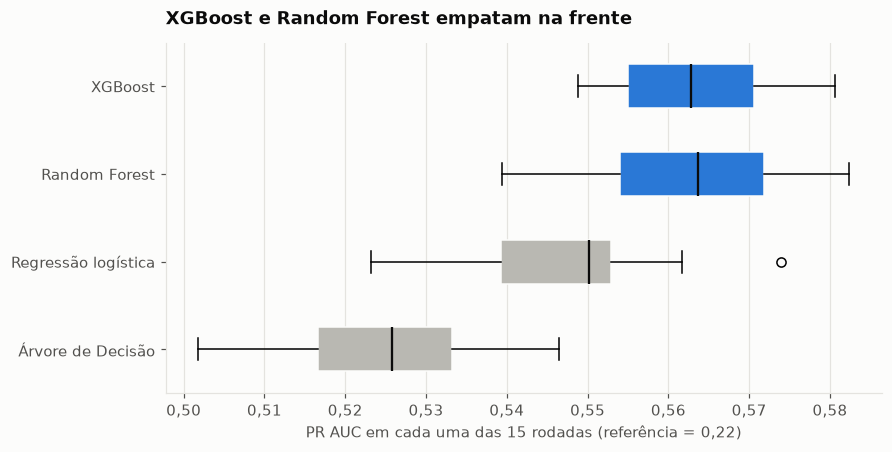

In [3]:
order = [m for m in summary["modelo"] if m != "dummy"]
leader = order[0]
fig, ax = plt.subplots(figsize=(8, 4))
data = [folds.loc[folds["modelo"] == m, "pr_auc"] for m in order]
bp = ax.boxplot(
    data,
    orientation="horizontal",
    patch_artist=True,
    widths=0.5,
    medianprops={"color": "#0b0b0b", "linewidth": 1.5},
)
for patch, m in zip(bp["boxes"], order, strict=True):
    patch.set_facecolor(HIGHLIGHT if m in ("xgboost", "random_forest") else CONTEXT)
    patch.set_edgecolor(SURFACE)
ax.set_yticks(range(1, len(order) + 1), [CATALOG[m].label for m in order])
ax.invert_yaxis()
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.2f}".replace(".", ",")))
ax.set_xlabel("PR AUC em cada uma das 15 rodadas (referência = 0,22)")
ax.set_title("XGBoost e Random Forest empatam na frente")
save(fig, "model_01_duelo_pr_auc")

**O que encontrei:**
- **XGBoost** lidera em PR AUC (0,5626), mas a **Random Forest** fica a 0,0003 e vence o XGBoost em **8 das 15 rodadas** (53%): **empate** pelo critério. Ela é até um pouco melhor em ROC AUC, KS e Brier.
- A **logística** perde para o XGBoost em todas as 15 rodadas, mas por pouco (−0,015). A **Árvore de Decisão** fica atrás de todos.
- A hipótese registrada antes se confirma: XGBoost ≈ Random Forest > logística > árvore.
- Todos ficam **muito acima da referência** (0,22): o modelo sabe algo que a taxa média não sabe.

**O que decidi:** **XGBoost e Random Forest seguem empatados para o tuning** (Etapa 11). A logística continua como modelo **interpretável** de comparação.

## 2. Por que a acurácia engana (de novo, agora com modelos)

PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/model_02_acuracia_engana.png')

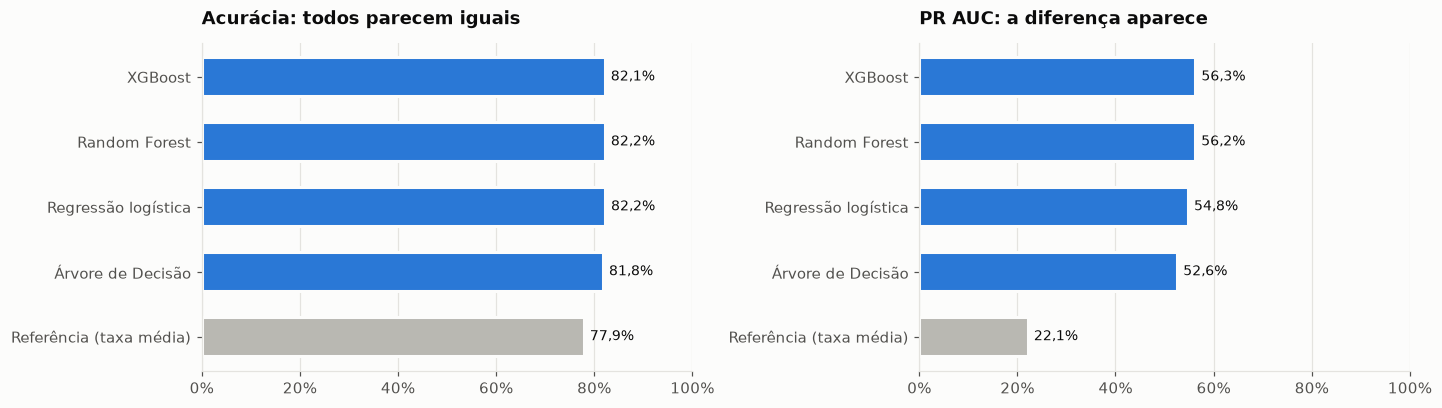

In [4]:
plot = summary.set_index("modelo").loc[order + ["dummy"]]
labels = [CATALOG[m].label for m in plot.index]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, metric, title in [
    (axes[0], "accuracy_media", "Acurácia: todos parecem iguais"),
    (axes[1], "pr_auc_media", "PR AUC: a diferença aparece"),
]:
    colors = [CONTEXT if m == "dummy" else HIGHLIGHT for m in plot.index]
    ax.barh(labels, plot[metric], color=colors, height=0.6, edgecolor=SURFACE, linewidth=2)
    for i, v in enumerate(plot[metric]):
        ax.annotate(
            pct(v), (v, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9
        )
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: pct(v, 0)))
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
save(fig, "model_02_acuracia_engana")

**O que encontrei:** a acurácia dos quatro modelos fica entre 81,8% e 82,2%, só 4 p.p. acima de "ninguém dá calote" (77,9%). O modelo com **maior acurácia é a logística**, que tem PR AUC **pior** que os dois líderes. Já o PR AUC separa claramente os modelos da referência (0,22 → 0,56).

**Por quê:** a acurácia usa um corte fixo em 50% e conta acertos iguais para os dois lados. Com 78% de bons pagadores, acertar "não vai dar calote" é fácil. O que o negócio precisa é **ordenar o risco** e ter **probabilidades confiáveis** para calcular o custo (Etapa 12).

## 3. O que a regressão logística ensina: razões de chances

A grande vantagem da logística é ser **interpretável**: cada variável recebe um peso, e `exp(peso)` é a **razão de chances** (*odds ratio*), o número pelo qual a chance de calote é multiplicada quando a variável aumenta 1 unidade, mantendo as outras iguais.

Exemplo: chance de 1 para 4 (20%) com razão de chances 2 vira 2 para 4 (33%).

### Primeiro, um cuidado: multicolinearidade

Se duas variáveis medem quase a mesma coisa (ex.: "pior atraso" e "meses com atraso"), o modelo divide o peso entre elas de forma arbitrária, e cada coeficiente sozinho perde o sentido. Isso **não prejudica a previsão**, só a leitura.

O **VIF** (*fator de inflação da variância*) mede isso. A ideia vem da álgebra linear: tenta-se explicar cada coluna com as outras (uma regressão). Se elas explicam 90% dela (R² = 0,9), o VIF é 1 ÷ (1 − 0,9) = **10**. Acima de 5 é o alerta usual.

In [5]:
E = engineered_features(df)
vif_all = vif_table(E)
vif_all.round(1).to_frame()

,vif
util_recent,19.2
pay_ratio_mean,18.2
util_mean,16.3
revolving_months,16.2
delay_months,10.4
pay_ratio_recent,5.9
delay_max,3.7
delay_recent,3.5
util_trend,3.5
paid_full_all,3.4


**O que encontrei:** várias features de resumo passam muito do alerta (VIF de 10 a 19). Faz sentido: meses no rotativo, meses com atraso e meses quitando somam 6, então um é quase determinado pelos outros. Na logística completa, por exemplo, `delay_months` (a variável mais forte sozinha) aparece com peso **negativo**, um artefato da colinearidade.

**O que decidi:** para **interpretar**, uso uma **logística enxuta** com 5 variáveis de VIF baixo, ajustada com `statsmodels` para ter intervalo de confiança em cada razão de chances. Para **prever**, os modelos completos continuam como estão.

In [6]:
X_int = E[config.INTERPRETABLE_FEATURES]
print("VIF do conjunto enxuto:")
print(vif_table(X_int).round(2).to_string())
odds = odds_ratio_table(X_int, y)
print(f"\npseudo-R²: {odds.attrs['pseudo_r2']:.3f}")
odds.round(4)

VIF do conjunto enxuto:
util_mean         2.65
pay_ratio_mean    2.46
delay_months      2.27
delay_recent      2.11
log_limit         1.28

pseudo-R²: 0.160


,razao_chances,ic_inf,ic_sup,p_valor
delay_recent,1.9926,1.8801,2.1118,0.0000
delay_months,1.3308,1.2937,1.3689,0.0000
log_limit,0.7794,0.7491,0.8108,0.0000
util_mean,1.1468,0.9790,1.3434,0.0896
pay_ratio_mean,1.2843,1.1190,1.4741,0.0004


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/model_03_razoes_chances.png')

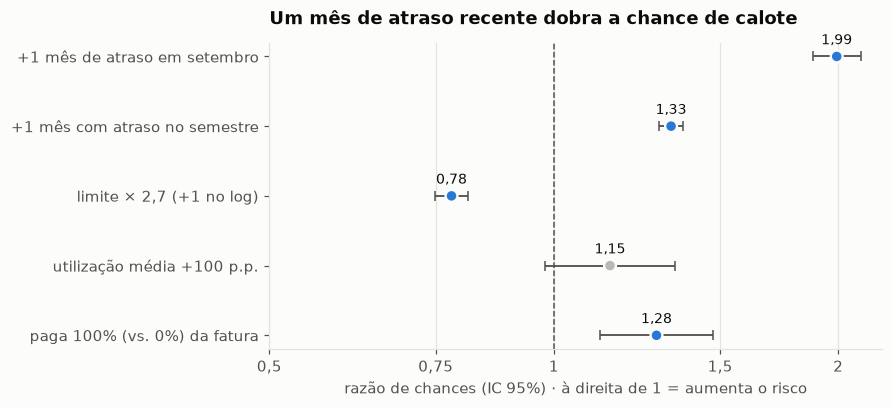

In [7]:
labels_or = {
    "delay_recent": "+1 mês de atraso em setembro",
    "delay_months": "+1 mês com atraso no semestre",
    "log_limit": "limite × 2,7 (+1 no log)",
    "util_mean": "utilização média +100 p.p.",
    "pay_ratio_mean": "paga 100% (vs. 0%) da fatura",
}
plot_or = odds.loc[config.INTERPRETABLE_FEATURES[::-1]]
fig, ax = plt.subplots(figsize=(8, 3.6))
ys = range(len(plot_or))
signif = plot_or["p_valor"] < config.ALPHA
ax.errorbar(
    plot_or["razao_chances"],
    ys,
    xerr=[
        plot_or["razao_chances"] - plot_or["ic_inf"],
        plot_or["ic_sup"] - plot_or["razao_chances"],
    ],
    fmt="none",
    ecolor=INK_2,
    elinewidth=1.2,
    capsize=3,
)
ax.scatter(
    plot_or["razao_chances"],
    ys,
    s=60,
    zorder=3,
    color=[HIGHLIGHT if s else CONTEXT for s in signif],
    edgecolor=SURFACE,
    linewidth=1.5,
)
for i, v in enumerate(plot_or["razao_chances"]):
    ax.annotate(
        f"{v:.2f}".replace(".", ","),
        (v, i),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )
ax.axvline(1, color=INK_2, linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xticks([0.5, 0.75, 1, 1.5, 2], ["0,5", "0,75", "1", "1,5", "2"])
ax.minorticks_off()
ax.set_yticks(list(ys), [labels_or[f] for f in plot_or.index])
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("razão de chances (IC 95%) · à direita de 1 = aumenta o risco")
ax.set_title("Um mês de atraso recente dobra a chance de calote")
save(fig, "model_03_razoes_chances")

**Leitura para o negócio** (cada efeito mantém as outras variáveis iguais):

| Variável | Razão de chances | Tradução |
|---|---|---|
| Atraso em setembro | **≈ 2,0** | cada mês de atraso no último pagamento **dobra** a chance de calote |
| Meses com atraso no semestre | **≈ 1,33** | cada mês do semestre com atraso aumenta a chance em cerca de 33%, **além** do atraso de setembro |
| Limite (log) | **≈ 0,78** | dobrar o limite reduz a chance em cerca de 16% (0,78 elevado a 0,69). Lembrete: é associação, não causa; o banco já dava limite maior a quem considerava melhor |
| Utilização média | ≈ 1,15, **não significativa** | depois de considerar o atraso, usar mais o limite não muda o risco de forma clara |
| Fração paga da fatura | **≈ 1,28** | ⚠️ **contraintuitivo**: sozinho, pagar mais "protege" (EDA); comparando clientes com o **mesmo atraso**, o efeito se inverte |

**O último achado é um caso clássico de confusão:** o efeito protetor de pagar a fatura era, em grande parte, **o atraso disfarçado**. Quem paga pouco costuma atrasar. Quando o modelo já sabe do atraso, pagar mais da fatura deixa de indicar menos risco. Fica registrado como resultado; não forço uma explicação.

O pseudo-R² de 0,16 parece baixo, mas é comum em crédito: o comportamento das pessoas tem muita variação que nenhum dado captura. O que importa para a decisão é **ordenar** bem o risco (PR AUC, KS) e ter **probabilidades confiáveis** (Brier, Etapa 12).

## 4. Conclusões da Etapa 9

| # | Achado | Decisão |
|---|---|---|
| 1 | XGBoost (PR AUC 0,563) e Random Forest (0,562) **empatam** (RF vence 53% das rodadas) | os dois seguem para o tuning |
| 2 | Logística 0,548 e Árvore de Decisão 0,526; todos muito acima da referência (0,22) | logística fica como modelo interpretável |
| 3 | Acurácia de 81,8% a 82,2% em todos; a **maior** é a da logística | acurácia não é critério de escolha |
| 4 | Features de resumo são muito colineares (VIF até 19) | coeficientes da logística completa não são lidos um a um |
| 5 | Logística enxuta: atraso recente **dobra** a chance; dobrar o limite reduz ≈ 16% | base para os motivos da decisão (Etapa 15) |
| 6 | Com o atraso no modelo, pagar mais da fatura não reduz o risco | o atraso é o que importa |

> **O que eu aprendi:** Eu esperava que o XGBoost ganhasse com folga; ele ficou 0,0003 à frente. Aprendi a declarar **empate por regra**, em vez de escolher o maior número da tabela.

## 5. Balancear as classes ajuda? (Etapa 10)

Só 22% dos clientes dão calote. Uma recomendação comum é **balancear** para o modelo "prestar mais atenção" nos inadimplentes:
- **Pesos por classe** (*class_weight*): cada erro num inadimplente conta cerca de 3,5 vezes mais no treino.
- **SMOTE**: cria inadimplentes **sintéticos**, interpolando entre inadimplentes parecidos, até as classes ficarem do mesmo tamanho. Aplicado **só no treino de cada fold**.

**O porém:** as duas técnicas fazem o modelo acreditar num mundo com 50% de caloteiros, e as probabilidades tendem a sair **infladas**. A decisão por custo (Etapa 12) multiplica a probabilidade pela dívida; probabilidade inflada vira ação em quem não precisa.

**Critério fixado antes:** adotar só se o PR AUC subir com win rate > 60% **e** o Brier não piorar (win rate ≥ 50%). **Hipótese:** não melhora o PR AUC e piora o Brier.

In [8]:
if RERUN_EXPERIMENTS:
    from credit_risk.experiments import balancing_calibration, balancing_experiment

    balancing_experiment()
    balancing_calibration()
decision = pd.read_csv(config.REPORTS_DIR / "balancing_decision.csv")
calib = pd.read_csv(config.REPORTS_DIR / "balancing_calibration.csv")
decision.round(4)

,modelo,estrategia,ganho_pr_auc,win_rate_pr_auc,ganho_brier,win_rate_brier,pr_auc_ok,brier_ok,adotar
0,logistic,class_weight,-0.0028,0.0000,-0.0478,0.0,False,False,False
1,logistic,smote,-0.0034,0.1333,-0.0478,0.0,False,False,False
2,random_forest,class_weight,0.0003,0.6000,-0.0391,0.0,False,False,False
3,random_forest,smote,-0.0143,0.0000,-0.0080,0.0,False,False,False
4,xgboost,class_weight,0.0005,0.5333,-0.0410,0.0,False,False,False
5,xgboost,smote,-0.0052,0.0667,-0.0017,0.0,False,False,False


In [9]:
mean_prob = calib.groupby(["modelo", "estrategia"])["media_prevista"].first().unstack()
mean_prob = mean_prob[["none", "class_weight", "smote"]]
mean_prob.index = [CATALOG[m].label for m in mean_prob.index]
print(f"Taxa real de default no treino: {y.mean():.2%}")
(mean_prob * 100).round(1).rename(
    columns={"none": "nenhum (%)", "class_weight": "class_weight (%)", "smote": "SMOTE (%)"}
)

Taxa real de default no treino: 22.12%


estrategia,nenhum (%),class_weight (%),SMOTE (%)
Regressão logística,22.1,43.3,43.1
Random Forest,22.2,40.7,29.1
XGBoost,22.1,40.8,25.0


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/model_04_confiabilidade_balanceamento.png')

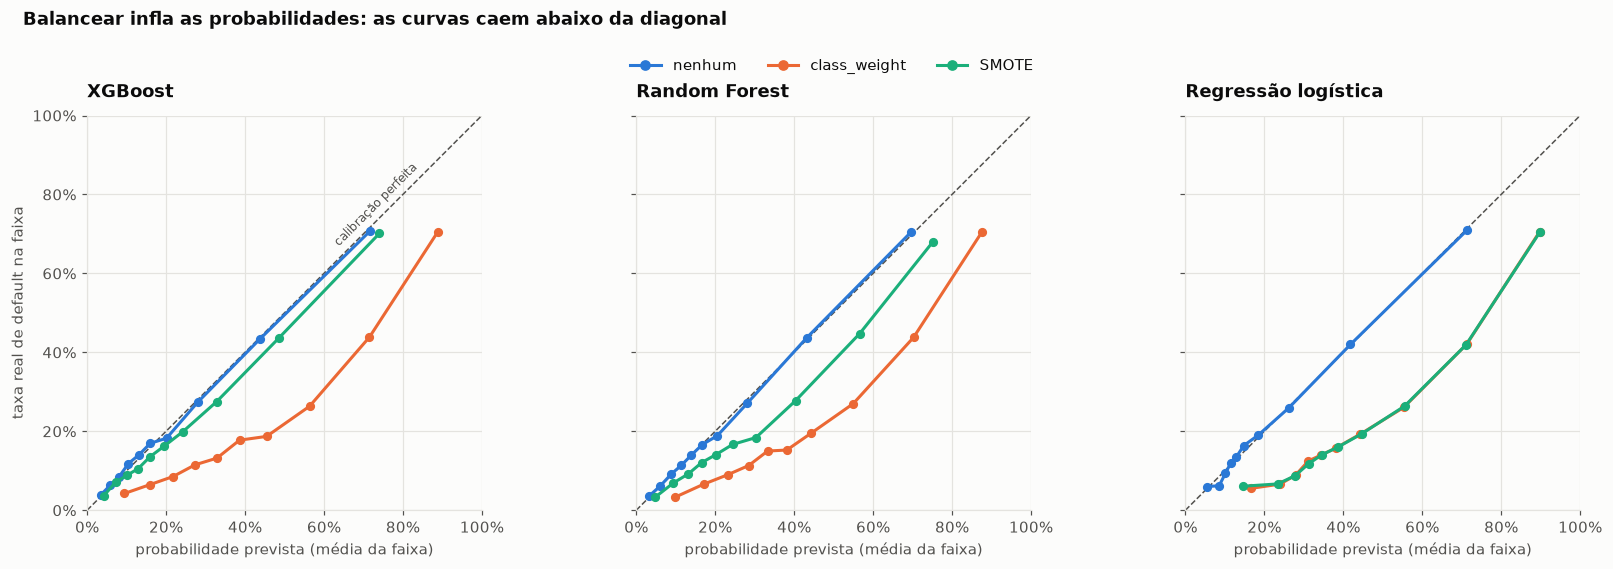

In [10]:
strategy_style = {
    "none": (HIGHLIGHT, "nenhum"),
    "class_weight": ("#eb6834", "class_weight"),
    "smote": ("#1baf7a", "SMOTE"),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, model in zip(axes, ["xgboost", "random_forest", "logistic"], strict=True):
    ax.plot([0, 1], [0, 1], color=INK_2, linestyle="--", linewidth=1)
    for strategy, (color, label) in strategy_style.items():
        part = calib[(calib["modelo"] == model) & (calib["estrategia"] == strategy)]
        ax.plot(
            part["prevista"],
            part["observada"],
            marker="o",
            markersize=5,
            linewidth=2,
            color=color,
            label=label,
        )
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: pct(v, 0)))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: pct(v, 0)))
    ax.grid(axis="x")
    ax.set_xlabel("probabilidade prevista (média da faixa)")
    ax.set_title(CATALOG[model].label)
axes[0].set_ylabel("taxa real de default na faixa")
axes[0].annotate("calibração perfeita", (0.62, 0.67), rotation=45, fontsize=8, color=INK_2)
handles = [plt.Line2D([], [], color=c, marker="o", linewidth=2) for c, _ in strategy_style.values()]
fig.legend(
    handles,
    [lbl for _, lbl in strategy_style.values()],
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(0.5, 1.07),
)
fig.suptitle(
    "Balancear infla as probabilidades: as curvas caem abaixo da diagonal",
    x=0.01,
    ha="left",
    fontweight="bold",
    y=1.14,
)
save(fig, "model_04_confiabilidade_balanceamento")

In [11]:
row = calib[(calib["modelo"] == "xgboost") & (calib["faixa"] == 6)].set_index("estrategia")
row[["prevista", "observada", "n"]].round(3)

,prevista,observada,n
estrategia,,,
none,0.201,0.182,2400
class_weight,0.455,0.187,2400
smote,0.243,0.199,2400


**O que encontrei:**
- **PR AUC:** nenhuma técnica melhora de forma consistente. O melhor caso (Random Forest + class_weight) ganha 0,0003 e vence em 60% das rodadas, sem passar do critério (> 60%). O SMOTE **piora** o PR AUC em quase todas as rodadas dos três modelos.
- **Brier:** piora em **100% das rodadas**, em todas as variantes. Com class_weight, o Brier do XGBoost (0,174) fica **pior que o da referência** que dá 22% para todo mundo (0,172).
- **Probabilidade média:** sem balanceamento, os modelos preveem em média **22%**, igual à taxa real. Com class_weight, **41% a 43%**. Na curva de confiabilidade, as linhas balanceadas ficam muito abaixo da diagonal. Na logística, class_weight e SMOTE produzem curvas praticamente iguais (se sobrepõem no gráfico).
- **Exemplo real** (XGBoost, 7ª faixa de risco): sem balanceamento o modelo diz 20% e a taxa real é 18%; com class_weight, diz **45%** para os mesmos clientes, cuja taxa real é **19%**.

**O que isso faria com o dinheiro** (exemplo ilustrativo, com valores hipotéticos): um cliente deve NT$ 10.000 e a perda em caso de calote seria de 60%. Com a probabilidade real de 19%, a perda esperada é 0,19 × 0,60 × 10.000 = **NT$ 1.140**. Com a probabilidade inflada de 45%, o cálculo diria **NT$ 2.700**, mais que o dobro, e a política agiria em muitos clientes que não precisam.

**O que decidi:** **nenhum balanceamento** (`config.BALANCING_STRATEGY = "none"`). A hipótese se confirmou nos dois pontos. Para achar mais inadimplentes, o caminho certo é **mover o limiar de decisão** (Etapa 12) com probabilidades calibradas, e não distorcer o treino.

> **O que eu aprendi:** Balancear as classes é uma receita comum, e aqui seria um erro caro: neste problema a probabilidade importa tanto quanto a ordem, porque ela vira dinheiro.

## 6. Ajuste fino dos hiperparâmetros (Etapa 11, Parte A)

Até aqui os modelos usaram configurações "de fábrica". O **tuning** testa combinações de hiperparâmetros e fica com a melhor:
- **Grid** (testa todas as combinações) para a logística (7 valores de `C`) e para a árvore (24 combinações);
- **Randomized** (sorteia combinações num espaço amplo) para a Random Forest (40) e o XGBoost (60).

**O risco: o otimismo da busca.** Escolher o melhor entre 60 candidatos é como jogar 60 dados e ficar com o maior: parte da "vitória" é sorte nos folds usados. Por isso a busca usa folds sorteados com **outra semente** (2024), e a versão escolhida é reavaliada nos **folds padrão** (semente 42), que a busca nunca viu. A diferença entre as duas notas é o **otimismo**.

**Critério fixado antes:** a versão ajustada substitui a padrão só se o PR AUC subir com win rate > 60% e o Brier não piorar. **Hipóteses:** ganho ≤ 0,01; otimismo positivo.

In [12]:
if RERUN_EXPERIMENTS:
    from credit_risk.tuning import run_tuning, tuned_leader_duel

    run_tuning()
    tuned_leader_duel()
tuning = pd.read_csv(config.REPORTS_DIR / "tuning_results.csv")
tuning.drop(columns="params").round(4)

,modelo,candidatos,pr_auc_busca,pr_auc_padrao,pr_auc_ajustado,otimismo,ganho_pr_auc,win_rate_pr_auc,ganho_brier,win_rate_brier,adotar
0,logistic,7,0.5468,0.5476,0.5476,-0.0007,0.0000,0.0000,0.0000,0.0000,False
1,decision_tree,24,0.5410,0.5256,0.5376,0.0034,0.0120,1.0000,0.0006,0.7333,True
2,random_forest,40,0.5652,0.5623,0.5642,0.0010,0.0019,0.6667,0.0001,0.7333,True
3,xgboost,60,0.5662,0.5626,0.5657,0.0005,0.0031,0.7333,0.0002,0.7333,True


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/model_05_tuning.png')

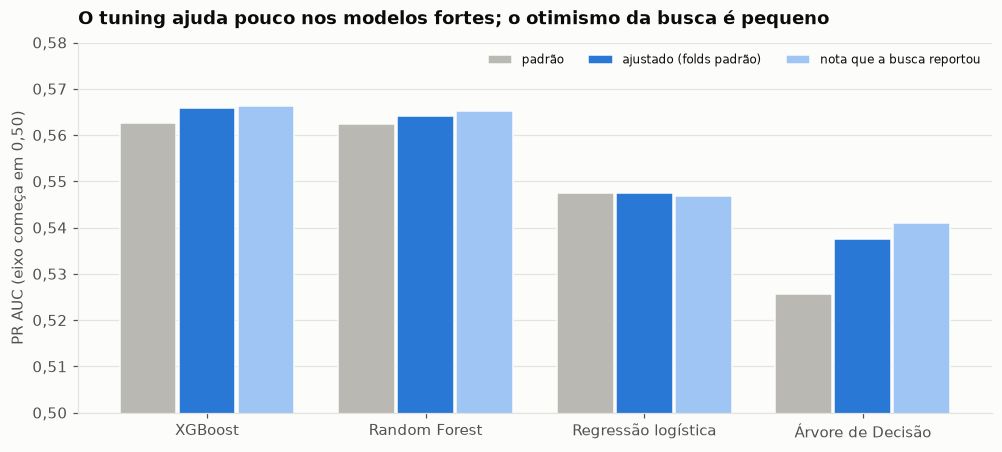

In [13]:
tun = tuning.set_index("modelo").loc[["xgboost", "random_forest", "logistic", "decision_tree"]]
labels_t = [CATALOG[m].label for m in tun.index]
x = np.arange(len(tun))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - 0.27, tun["pr_auc_padrao"], 0.26, color=CONTEXT, label="padrão", edgecolor=SURFACE)
ax.bar(
    x,
    tun["pr_auc_ajustado"],
    0.26,
    color=HIGHLIGHT,
    label="ajustado (folds padrão)",
    edgecolor=SURFACE,
)
ax.bar(
    x + 0.27,
    tun["pr_auc_busca"],
    0.26,
    color="#9ec5f4",
    label="nota que a busca reportou",
    edgecolor=SURFACE,
)
ax.set_xticks(x, labels_t)
ax.set_ylim(0.50, 0.58)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.2f}".replace(".", ",")))
ax.set_ylabel("PR AUC (eixo começa em 0,50)")
ax.legend(loc="upper right", ncol=3, fontsize=8)
ax.set_title("O tuning ajuda pouco nos modelos fortes; o otimismo da busca é pequeno")
save(fig, "model_05_tuning")

In [14]:
duel = pd.read_csv(config.REPORTS_DIR / "tuned_duel.csv")
duel.round(4)

,lider,rival,métrica,base,candidato,ganho_medio,desvio_ganho,win_rate
0,xgboost,random_forest,pr_auc,0.5657,0.5642,-0.0016,0.0031,0.3333
1,xgboost,random_forest,roc_auc,0.7885,0.7874,-0.0011,0.0009,0.0667
2,xgboost,random_forest,ks,0.4401,0.4391,-0.0010,0.0040,0.4000
3,xgboost,random_forest,brier,0.1330,0.1331,-0.0001,0.0004,0.4667


**O que encontrei:**
- **XGBoost:** 0,5626 → **0,5657** (+0,003, vence em 73% das rodadas). **Random Forest:** 0,5623 → **0,5642** (+0,002, 67%). Os dois passam no critério, sem piorar o Brier.
- **Árvore de Decisão:** o maior ganho (+0,012, 100% das rodadas), justamente o modelo mais sensível à configuração. A busca escolheu árvores mais profundas (10 níveis) com folhas maiores (≥ 200 clientes).
- **Logística:** a busca escolheu **C = 1**, o próprio valor padrão. Não há o que adotar.
- **Otimismo:** a nota da busca fica 0,0005 a 0,0034 **acima** da nota real nos folds independentes, como esperado. Na logística ele saiu levemente **negativo** (−0,0007): com só 7 candidatos, a "sorte" da escolha quase não atua, e o que aparece é a variação natural entre sorteios de folds. Hipótese **parcialmente** confirmada: o otimismo existe, mas é pequeno nestes dados.
- **Depois do tuning, o empate se desfaz:** a Random Forest ajustada vence o XGBoost ajustado em só **33%** das rodadas de PR AUC (abaixo dos 40% para empate) e em 1 de 15 em ROC AUC.

**O que decidi:** hiperparâmetros ajustados adotados para XGBoost, Random Forest e árvore (`reports/best_params.json`). **O XGBoost ajustado é o líder isolado** e o modelo de referência para a Parte B (combinação) e para a calibração (Etapa 12).

> **O que eu aprendi:** O ajuste fino rendeu pouco nos modelos fortes. Medir o otimismo da busca me mostrou quanto de uma "melhora" pode ser só sorte na escolha.

## 7. Combinar modelos ajuda? (Etapa 11, Parte B)

**A ideia:** num júri, se três jurados olham as mesmas pistas e pensam igual, ouvir os três é como ouvir um só. A combinação (*ensemble*) só ajuda quando os modelos **erram em clientes diferentes**.

Primeiro meço a **diversidade**: a correlação entre os erros out-of-fold de cada par de modelos ajustados (erro = o que aconteceu − probabilidade prevista). Correlação perto de 1 = erram juntos.

In [15]:
if RERUN_EXPERIMENTS:
    from credit_risk.experiments import ensemble_diversity, ensemble_experiment

    ensemble_diversity()
    ensemble_experiment()
diversity = pd.read_csv(config.REPORTS_DIR / "ensemble_diversity.csv", index_col=0)
diversity.index = diversity.columns = [CATALOG[m].label for m in diversity.columns]
diversity.round(3)

,XGBoost,Random Forest,Regressão logística,Árvore de Decisão
XGBoost,1.000,0.998,0.988,0.986
Random Forest,0.998,1.000,0.986,0.987
Regressão logística,0.988,0.986,1.000,0.976
Árvore de Decisão,0.986,0.987,0.976,1.000


**O que encontrei:** os erros têm correlação de **0,976 a 0,998**. XGBoost e Random Forest (**0,998**) erram praticamente nos mesmos clientes: aprenderam a mesma coisa por caminhos diferentes. Mesmo a logística, que "pensa" de forma linear, erra quase igual (0,988). A hipótese registrada antes se confirma: há pouca diversidade para explorar.

### O teste

| Variante | Como combina |
|---|---|
| Votação soft XGBoost + RF | média das duas probabilidades |
| Votação soft XGBoost + RF + logística | média das três (a logística traz um pouco de diversidade) |
| Stacking dos três | uma logística aprende quanto confiar em cada modelo, usando previsões out-of-fold feitas **dentro** do treino |

**Critério fixado antes:** adotar só se vencer o **XGBoost ajustado** com win rate > 60% em PR AUC **e** sem piorar o Brier. Um ensemble é mais caro de manter e de explicar; ele precisa provar que vale.

In [16]:
ens = pd.read_csv(config.REPORTS_DIR / "ensemble_experiment.csv")
decision_e = pd.read_csv(config.REPORTS_DIR / "ensemble_decision.csv")
decision_e.round(4)

,modelo,estrategia,ganho_pr_auc,win_rate_pr_auc,ganho_brier,win_rate_brier,pr_auc_ok,brier_ok,adotar
0,xgboost,stacking_xgb_rf_logit,0.0009,0.7333,-0.0007,0.1333,True,False,False
1,xgboost,voting_xgb_rf,0.0002,0.4667,0.0001,0.6000,False,True,False
2,xgboost,voting_xgb_rf_logit,0.0009,0.6000,0.0001,0.7333,False,True,False


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/model_06_ensembles.png')

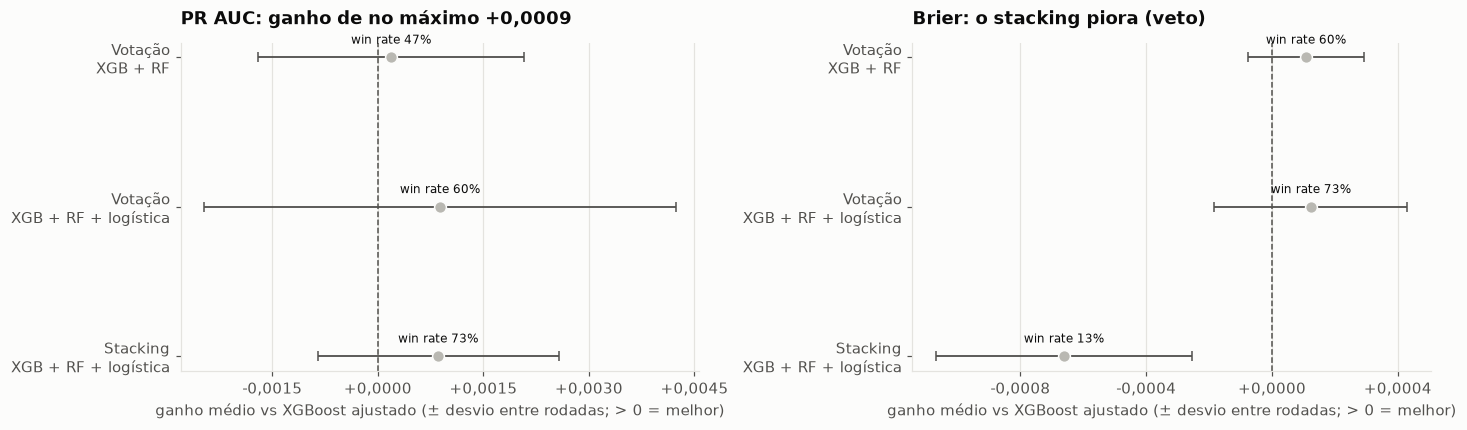

In [17]:
names_e = {
    "voting_xgb_rf": "Votação\nXGB + RF",
    "voting_xgb_rf_logit": "Votação\nXGB + RF + logística",
    "stacking_xgb_rf_logit": "Stacking\nXGB + RF + logística",
}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, metric, title in [
    (axes[0], "pr_auc", "PR AUC: ganho de no máximo +0,0009"),
    (axes[1], "brier", "Brier: o stacking piora (veto)"),
]:
    part = ens[ens["métrica"] == metric].set_index("estrategia").loc[list(names_e)]
    ys = range(len(part))
    ax.errorbar(
        part["ganho_medio"],
        ys,
        xerr=part["desvio_ganho"],
        fmt="none",
        ecolor=INK_2,
        elinewidth=1.2,
        capsize=3,
    )
    ax.scatter(part["ganho_medio"], ys, s=60, color=CONTEXT, edgecolor=SURFACE, zorder=3)
    for i, (g, w) in enumerate(zip(part["ganho_medio"], part["win_rate"], strict=True)):
        ax.annotate(
            f"win rate {pct(w, 0)}",
            (g, i),
            xytext=(0, 9),
            textcoords="offset points",
            ha="center",
            fontsize=8,
        )
    ax.axvline(0, color=INK_2, linestyle="--", linewidth=1)
    ax.set_yticks(list(ys), list(names_e.values()))
    ax.invert_yaxis()
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.4f}".replace(".", ",")))
    ax.set_xlabel("ganho médio vs XGBoost ajustado (± desvio entre rodadas; > 0 = melhor)")
    ax.set_title(title)
save(fig, "model_06_ensembles")

**O que encontrei:**
- **Votação XGB + RF:** +0,0002 em PR AUC, vence em 47% das rodadas. Previsível: os dois erram juntos.
- **Votação com a logística:** +0,0009, vence em **exatamente 60%** das rodadas, sem passar do critério (> 60%).
- **Stacking:** +0,0009 e vence em 73% das rodadas em PR AUC (passaria), mas **piora o Brier em 13 de 15 rodadas**. A logística do topo, treinada sobre previsões que já eram calibradas, distorce um pouco as probabilidades. É o **veto da calibração** fazendo o papel para o qual foi criado.
- Em todos os casos, o ganho (≤ 0,0009) é **menor que a variação natural** entre rodadas (desvio de 0,0017 a 0,0033).

**O que decidi:** **nenhum ensemble é adotado.** O modelo final é o **XGBoost ajustado, sozinho** (`config.FINAL_MODEL`). Três modelos custariam mais para treinar, monitorar e explicar (os motivos de cada decisão, na Etapa 15, ficariam bem mais difíceis) em troca de um ganho que não se distingue do ruído.

> **O que eu aprendi:** Antes de combinar modelos, vale medir se eles erram em clientes diferentes. Aqui não erravam, e o teste confirmou o que a diversidade já anunciava.

## 8. Calibração das probabilidades (Etapa 12, Parte A)

*A partir da Etapa 13A, o modelo final não usa sexo, estado civil nem idade. Os números desta seção foram recalculados com esse modelo; as decisões não mudaram.*

A partir daqui, a probabilidade vira dinheiro: perda esperada = PD × LGD × EAD. Se o modelo diz "30%", precisa ser verdade que cerca de 30% desses clientes dão calote. Isso é **calibração**.

A Etapa 10 mostrou que os modelos já saem quase calibrados. Mesmo assim testo as duas correções clássicas no XGBoost ajustado:
- **Sigmoid** (método de Platt): corrige com uma curva em "S". É suave e precisa de poucos dados.
- **Isotônica**: corrige com uma "escada" livre, sempre crescente. É mais flexível, mas pode se ajustar ao ruído.

A correção é aprendida em partes do treino que o modelo não viu (validação cruzada interna), sem vazamento.

**Critério fixado antes:** adotar se o Brier melhorar com win rate > 60% **sem piorar o PR AUC** (win rate ≥ 50%; a correção não deveria mudar a ordem dos clientes). **Hipótese:** nenhuma ajuda.

In [18]:
if RERUN_EXPERIMENTS:
    from credit_risk.experiments import calibration_experiment

    calibration_experiment()
cal_exp = pd.read_csv(config.REPORTS_DIR / "calibration_experiment.csv")
cal_dec = pd.read_csv(config.REPORTS_DIR / "calibration_decision.csv")
cal_rel = pd.read_csv(config.REPORTS_DIR / "calibration_reliability.csv")
cal_dec.round(4)

,método,ganho_brier,win_rate_brier,ganho_pr_auc,win_rate_pr_auc,adotar
0,isotonic,0.0001,0.6667,-0.0013,0.2000,False
1,sigmoid,-0.0006,0.0000,0.0005,0.6667,False


In [19]:
cal_rel["erro"] = (cal_rel["prevista"] - cal_rel["observada"]).abs()
cal_rel.groupby("método").agg(
    media_prevista=("media_prevista", "first"),
    erro_medio_pp=("erro", lambda e: 100 * e.mean()),
    pior_faixa_pp=("erro", lambda e: 100 * e.max()),
).round(2)

,media_prevista,erro_medio_pp,pior_faixa_pp
método,,,
isotonic,0.22,0.23,0.60
none,0.22,1.18,3.48
sigmoid,0.22,2.48,4.70


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/model_07_calibracao.png')

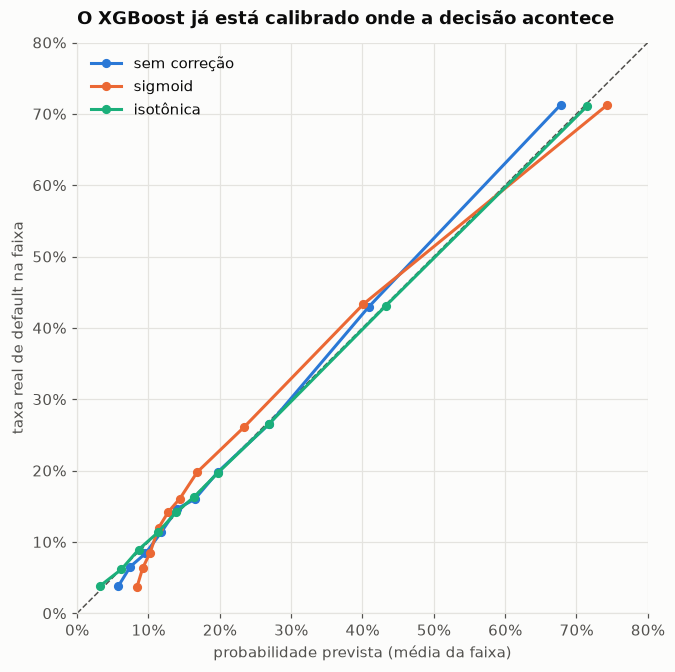

In [20]:
method_style = {
    "none": (HIGHLIGHT, "sem correção"),
    "sigmoid": ("#eb6834", "sigmoid"),
    "isotonic": ("#1baf7a", "isotônica"),
}
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], color=INK_2, linestyle="--", linewidth=1)
for method, (color, label) in method_style.items():
    part = cal_rel[cal_rel["método"] == method]
    ax.plot(
        part["prevista"],
        part["observada"],
        marker="o",
        markersize=5,
        linewidth=2,
        color=color,
        label=label,
    )
ax.set_xlim(0, 0.8)
ax.set_ylim(0, 0.8)
ax.set_aspect("equal")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: pct(v, 0)))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: pct(v, 0)))
ax.grid(axis="x")
ax.legend(loc="upper left")
ax.set_xlabel("probabilidade prevista (média da faixa)")
ax.set_ylabel("taxa real de default na faixa")
ax.set_title("O XGBoost já está calibrado onde a decisão acontece")
save(fig, "model_07_calibracao")

**O que encontrei:**
- **Sigmoid:** piora o Brier em **todas** as 15 rodadas (0,1332 → 0,1338). Ela supõe uma distorção em "S" que o modelo não tem.
- **Isotônica:** melhora o Brier em 67% das rodadas, mas o ganho é mínimo (0,0001) e o PR AUC **piora em 80% das rodadas**, então não passa no critério.
- Na curva, o modelo sem correção é levemente "comprimido" nas pontas: na faixa de menor risco prevê 5,7% (real 3,8%); na de maior risco, 67,8% (real 71,3%). **Entre 10% e 30%, onde a decisão de agir acontece, o erro é praticamente zero** (≤ 0,7 p.p.). A isotônica corrige as pontas (erro médio de 0,2 p.p. contra 1,2 p.p.).

**O que decidi:** **sem correção** (`config.CALIBRATION_METHOD = "none"`), pelo critério fixado. A regra não muda depois de ver o resultado. Como checagem de **robustez**, a Parte B calcula o resultado financeiro também com a isotônica, para mostrar se a diferença nas pontas mudaria alguma decisão em dinheiro.

> **O que eu aprendi:** Calibrar "por garantia" pode piorar o modelo. Testar antes de aplicar evitou isso.

## 9. Da probabilidade ao dinheiro: a política de decisão (Etapa 12, Parte B)

*A partir da Etapa 13A, o modelo final não usa sexo, estado civil nem idade. Os números desta seção foram recalculados com esse modelo; as decisões não mudaram.*

**Para cada cliente: vale a pena agir?** Agir (contato, renegociação) evita parte da perda de quem daria calote, mas custa dinheiro e incomoda quem pagaria.

**Premissas de negócio** (em `config.py`; testadas na sensibilidade abaixo):

| Premissa | Valor | O que é |
|---|---|---|
| LGD | 60% | fração da dívida perdida no calote (*Loss Given Default*) |
| EAD | fatura de setembro (negativa → 0) | quanto o cliente deve na hora do calote (*Exposure at Default*) |
| Eficácia da ação | 30% | fração da perda que a ação evita num caloteiro |
| Custo da ação | NT$ 100 | por cliente acionado |
| Atrito | NT$ 300 | margem perdida ao acionar um bom pagador |

**O valor de agir**, com uma fatura de NT$ 10.000:
- se o cliente **daria calote**: 0,60 × 10.000 × 0,30 − 100 = **+NT$ 1.700**;
- se **pagaria**: −100 − 300 = **−NT$ 400**.

Com a PD do modelo, o **valor esperado** de agir é PD × 1.800 − 100 − (1 − PD) × 300. Ele é positivo quando a PD passa de 400 ÷ 2.100 ≈ **19%**. Com uma fatura de NT$ 2.000, esse ponto sobe para cerca de 62%: **o limiar depende do valor em jogo.**

Tudo é calculado nas previsões **out-of-fold** do treino. O holdout só confirma (Etapa 13).

In [21]:
if RERUN_EXPERIMENTS:
    from credit_risk.experiments import capacity_experiment, decision_experiment

    decision_experiment()
    capacity_experiment()
policies = pd.read_csv(config.REPORTS_DIR / "decision_policies.csv")
show = policies.assign(valor_mi=policies["valor"] / 1e6)
show[["política", "acionados", "pct_acionados", "pct_calotes_alcancados", "valor_mi"]].round(3)

,política,acionados,pct_acionados,pct_calotes_alcancados,valor_mi
0,não agir,0,0.000,0.000,0.000
1,agir em todos,24000,1.000,1.000,37.837
2,"limiar 0,5",2687,0.112,0.350,18.888
3,melhor limiar único (0.01),24000,1.000,1.000,37.837
4,regra por cliente (valor esperado > 0),14249,0.594,0.690,40.430
5,melhor regra fixa: meses com atraso >= 1,8104,0.338,0.655,27.067


In [22]:
boot = pd.read_csv(config.REPORTS_DIR / "decision_bootstrap.csv")
boot[["diferença", "ic_inf", "ic_sup"]] = boot[["diferença", "ic_inf", "ic_sup"]] / 1e6
robust = pd.read_csv(config.REPORTS_DIR / "decision_robustness.csv")
print(f"Perda total sem ação (treino): NT$ {policies['perda_sem_acao'].iloc[0] / 1e6:.1f} mi")
display(boot.round(2))
robust.assign(valor_mi=robust["valor"] / 1e6)[["probabilidade", "pct_acionados", "valor_mi"]].round(
    3
)

Perda total sem ação (treino): NT$ 152.8 mi


,comparação,diferença,ic_inf,ic_sup
0,regra por cliente − não agir,40.43,38.28,42.67
1,regra por cliente − melhor regra fixa,13.36,11.92,14.83
2,regra por cliente − melhor limiar único,2.59,2.49,2.69
3,melhor limiar único − melhor regra fixa,10.77,9.33,12.25


,probabilidade,pct_acionados,valor_mi
0,sem correção,0.594,40.430
1,isotônica,0.562,40.425


**O que encontrei (sem limite de capacidade):**
- A regra por cliente (agir se o valor esperado for positivo) gera **+NT$ 40,4 mi** contra não agir (IC 95%: 38,3 a 42,7 mi) e **+NT$ 13,4 mi** contra a melhor regra fixa ("≥ 1 mês com atraso"; IC 11,9 a 14,8 mi). O critério de sucesso da Etapa 1 está cumprido.
- **Mas há um problema de realismo:** com estas premissas, acionar um caloteiro típico evita cerca de NT$ 3.600, e acionar um bom pagador custa só NT$ 400. Agir compensa a partir de ≈ 10% de PD, e a carteira tem 22%. Por isso a política aciona **59% da carteira**, e o "melhor limiar único" degenera para 0,01 (agir em todos).
- **Robustez da calibração:** com a isotônica, o valor muda 0,01% (40,43 → 40,43 mi). A escolha da Parte A não afeta a decisão.

Nenhuma operação aciona 60% dos clientes por mês. **O que decidi (depois de ver este resultado, por isso registrado):** manter as premissas e acrescentar uma **restrição de capacidade**: a equipe aciona no máximo **10%** da carteira por mês (sensibilidade em 5% e 20%). A pergunta passa a ser: **com o mesmo número de ações, quem acionar?**

### Com capacidade limitada: quem acionar?

Três formas de escolher os 10%:
- **Maior valor esperado** (modelo): PD × valor em jogo, entre os de valor esperado positivo;
- **Maior PD** (modelo): só a probabilidade;
- **Regra de atraso** (sem modelo): mais atrasado em setembro primeiro, depois mais meses com atraso e, no empate, a maior fatura (o "bom senso" de um analista).

**Critério fixado antes de rodar:** o valor esperado precisa vencer a regra de atraso com IC 95% acima de zero.

In [23]:
cap = pd.read_csv(config.REPORTS_DIR / "decision_capacity.csv")
cap_boot = pd.read_csv(config.REPORTS_DIR / "decision_capacity_bootstrap.csv")
cap_boot[["diferença", "ic_inf", "ic_sup"]] = cap_boot[["diferença", "ic_inf", "ic_sup"]] / 1e6
display(
    cap.assign(valor_mi=cap["valor"] / 1e6)[
        ["capacidade", "política", "calotes_alcancados", "pct_calotes_alcancados", "valor_mi"]
    ].round(3)
)
cap_boot.round(2)

,capacidade,política,calotes_alcancados,pct_calotes_alcancados,valor_mi
0,0.05,maior valor esperado (modelo),657,0.124,19.110
1,0.05,maior PD (modelo),914,0.172,7.120
2,0.05,regra de atraso (sem modelo),881,0.166,9.034
3,0.10,maior valor esperado (modelo),1142,0.215,26.668
4,0.10,maior PD (modelo),1711,0.322,17.944
5,0.10,regra de atraso (sem modelo),1701,0.320,18.951
6,0.20,maior valor esperado (modelo),1885,0.355,34.016
7,0.20,maior PD (modelo),2741,0.516,23.187
8,0.20,regra de atraso (sem modelo),2606,0.491,23.797


,capacidade,comparação,diferença,ic_inf,ic_sup
0,0.05,maior valor esperado (modelo) − regra de atras...,10.08,8.55,11.60
1,0.05,maior valor esperado (modelo) − maior PD (modelo),11.99,10.32,13.71
2,0.05,maior PD (modelo) − regra de atraso (sem modelo),-1.91,-2.76,-1.10
3,0.10,maior valor esperado (modelo) − regra de atras...,7.72,6.34,9.15
4,0.10,maior valor esperado (modelo) − maior PD (modelo),8.72,7.26,10.25
5,0.10,maior PD (modelo) − regra de atraso (sem modelo),-1.01,-1.58,-0.50
6,0.20,maior valor esperado (modelo) − regra de atras...,10.22,8.80,11.68
7,0.20,maior valor esperado (modelo) − maior PD (modelo),10.83,9.39,12.32
8,0.20,maior PD (modelo) − regra de atraso (sem modelo),-0.61,-1.09,-0.17


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/decision_01_capacidade.png')

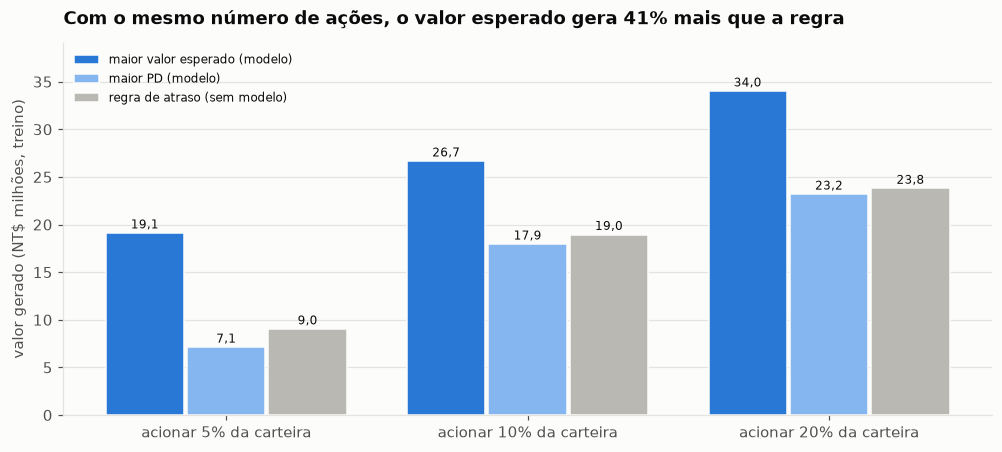

In [24]:
pol_style = {
    "maior valor esperado (modelo)": HIGHLIGHT,
    "maior PD (modelo)": "#86b6ef",
    "regra de atraso (sem modelo)": CONTEXT,
}
caps = config.CAPACITY_SENSITIVITY
xs = np.arange(len(caps))
fig, ax = plt.subplots(figsize=(9, 4))
for i, (pol, color) in enumerate(pol_style.items()):
    vals = [
        cap[(cap["capacidade"] == c) & (cap["política"] == pol)]["valor"].iloc[0] / 1e6
        for c in caps
    ]
    bars = ax.bar(xs + (i - 1) * 0.27, vals, 0.26, color=color, label=pol, edgecolor=SURFACE)
    for b, v in zip(bars, vals, strict=True):
        ax.annotate(
            f"{v:.1f}".replace(".", ","),
            (b.get_x() + b.get_width() / 2, v),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            fontsize=8,
        )
ax.set_xticks(xs, [f"acionar {pct(c, 0)} da carteira" for c in caps])
ax.set_ylabel("valor gerado (NT$ milhões, treino)")
ax.legend(loc="upper left", fontsize=8)
ax.margins(y=0.15)
ax.set_title("Com o mesmo número de ações, o valor esperado gera 41% mais que a regra")
save(fig, "decision_01_capacidade")

**O que encontrei (capacidade de 10%, 2.400 clientes por mês):**

| Política | Calotes alcançados | Valor |
|---|---|---|
| **Maior valor esperado** | 1.142 (21,5%) | **NT$ 26,7 mi** |
| Maior PD | 1.711 (32,2%) | NT$ 17,9 mi |
| Regra de atraso | 1.701 (32,0%) | NT$ 19,0 mi |

- **Critério cumprido nas três capacidades:** valor esperado − regra de atraso = **+NT$ 7,7 mi** com 10% (IC 6,3 a 9,2 mi), +10,1 mi com 5% e +10,2 mi com 20%.
- ⚠️ **Contraintuitivo:** ordenar **só pela PD perde da regra de atraso** em dinheiro, com IC inteiramente abaixo de zero (−1,0 mi com 10%). A regra desempata pela maior fatura, ou seja, já considera o valor em jogo; a PD pura ignora isso.
- A política vencedora **acha menos calotes** (1.142 contra 1.701), mas acha **os que custam mais caro**.

**Lição de negócio:** um bom modelo de risco, sozinho, **não basta**. O valor aparece quando a probabilidade é combinada com a exposição, que é exatamente a perda esperada (Etapa 14).

PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/decision_02_sensibilidade.png')

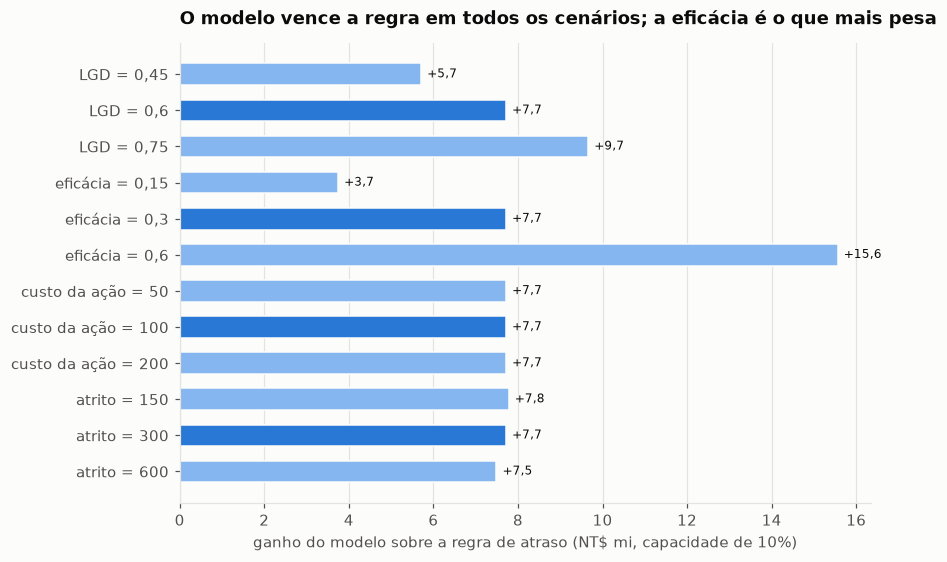

In [25]:
sens = pd.read_csv(config.REPORTS_DIR / "decision_capacity_sensitivity.csv")
labels_s = {
    "lgd": "LGD",
    "efficacy": "eficácia",
    "action_cost": "custo da ação",
    "friction_cost": "atrito",
}
sens["cenário"] = [
    f"{labels_s[p]} = {v:g}".replace(".", ",")
    for p, v in zip(sens["premissa"], sens["valor"], strict=True)
]
fig, ax = plt.subplots(figsize=(8, 5))
ys = np.arange(len(sens))
base_mask = [
    (p, v)
    in {
        ("lgd", config.LGD),
        ("efficacy", config.ACTION_EFFICACY),
        ("action_cost", config.ACTION_COST),
        ("friction_cost", config.FRICTION_COST),
    }
    for p, v in zip(sens["premissa"], sens["valor"], strict=True)
]
ax.barh(
    ys,
    sens["diferenca"] / 1e6,
    color=[HIGHLIGHT if b else "#86b6ef" for b in base_mask],
    height=0.6,
    edgecolor=SURFACE,
)
for y_, v in zip(ys, sens["diferenca"] / 1e6, strict=True):
    ax.annotate(
        f"+{v:.1f}".replace(".", ","),
        (v, y_),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
        fontsize=8,
    )
ax.set_yticks(ys, sens["cenário"])
ax.invert_yaxis()
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("ganho do modelo sobre a regra de atraso (NT$ mi, capacidade de 10%)")
ax.set_title("O modelo vence a regra em todos os cenários; a eficácia é o que mais pesa")
save(fig, "decision_02_sensibilidade")

**Sensibilidade (capacidade de 10%, uma premissa por vez; azul escuro = valor adotado):**
- O modelo vence a regra de atraso em **todos os 12 cenários**, de +NT$ 3,8 mi (eficácia de 15%) a +NT$ 15,6 mi (eficácia de 60%).
- A premissa que mais muda o resultado é a **eficácia da ação**; os custos de ação e de atrito quase não mexem (a capacidade já limita quantas ações acontecem).
- Com as premissas adotadas, a política evita **17,5%** da perda total da carteira (o teto teórico, com eficácia de 30% e sem custos, seria 30%).

**O que decidi:** a política oficial é **acionar, por mês, os 10% de clientes com maior valor esperado de ação** (`config.CAPACITY`). A Etapa 13 confirma no holdout; a Etapa 14 transforma isso em perda esperada, score e faixas.

> **O que eu aprendi:** Este é o resultado mais importante do projeto: o modelo com a melhor PD **perde** da regra de atraso até eu incluir o valor em jogo de cada cliente.

## 10. O modelo precisa de sexo, estado civil e idade? (Etapa 13, Parte A)

Até aqui o modelo usava sexo, estado civil e idade. Usar sexo ou estado civil para decidir sobre crédito é **eticamente questionável** e, em vários países, restrito por lei. No Brasil, a LGPD proíbe o tratamento de dados pessoais para fins discriminatórios. A idade é comum em modelos de crédito, mas também pede cuidado.

**Por que decidir agora, no treino:** se eu abrisse o holdout, visse um problema de equidade e só então tirasse uma variável, estaria escolhendo o modelo **olhando a prova**.

**Critério fixado antes (não inferioridade):** remover os atributos se o PR AUC cair **menos de 0,005** **e** o valor da política (capacidade de 10%) cair **menos de 2%**. Prefere-se a variante **mais restritiva** que passar. A preferência é ética: só os manteria se a perda fosse relevante.

In [26]:
if RERUN_EXPERIMENTS:
    from credit_risk.experiments import sensitive_experiment

    sensitive_experiment()
sens_attr = pd.read_csv(config.REPORTS_DIR / "sensitive_experiment.csv")
sens_attr.assign(valor_politica_mi=sens_attr["valor_politica"] / 1e6).drop(
    columns="valor_politica"
).round(4)

,variante,pr_auc,perda_pr_auc,win_rate_vs_atual,perda_valor_pct,nao_inferior,valor_politica_mi
0,atual,0.5657,-0.0000,0.0000,0.0000,True,26.6399
1,sem sexo e estado civil,0.5658,-0.0001,0.4667,-0.0027,True,26.7125
2,"sem sexo, estado civil e idade",0.5657,0.0000,0.4667,-0.0011,True,26.6679


**O que encontrei:** tirar os três atributos **não custa nada**. O PR AUC fica em 0,5657 (igual), o modelo sem eles vence o atual em 7 das 15 rodadas (um empate) e o valor da política fica até 0,1% **maior** (NT$ 26,67 mi contra 26,64 mi). Isso bate com a EDA, em que esses atributos tinham efeito desprezível.

**O que decidi:** o modelo final **não usa sexo, estado civil nem idade** (`config.MODEL_EXCLUDE`). A escolha ética não tem custo. Sexo e idade continuam nos dados **só para auditar** a equidade no holdout (Parte B).

O modelo oficial passa a ser `models.final_pipeline()`, a **única fonte de verdade** para decisão, API e dashboard. Os experimentos da Etapa 12 foram recalculados com ele; as decisões não mudaram, e os números das seções 8 e 9 já são os finais.

> **O que eu aprendi:** A escolha ética não custou nada. Decidir isso **antes** de abrir o holdout foi o que deu credibilidade à decisão.

## 11. A prova final: o holdout (Etapa 13, Parte B)

Os 6.000 clientes separados na Etapa 4 nunca participaram de nenhuma escolha. Agora o modelo oficial é treinado nos 24.000 clientes de treino e avaliado **uma única vez** neles. O código **se recusa** a reavaliar o holdout (`make final` falha se as métricas já existirem), e as etapas seguintes só **leem** as previsões salvas.

Este notebook **não** reavalia o holdout: ele lê os resultados salvos por `make final`.

**Critérios fixados antes de abrir:**
1. O PR AUC do holdout cai dentro da faixa da CV (média ± 1,96 × desvio dos 15 folds).
2. Na política de 10%, o valor esperado vence a regra de atraso com IC 95% acima de zero.
3. Equidade (auditoria): alerta se a calibração de algum grupo errar mais de 3 p.p., ou se o ROC AUC variar mais de 0,05 entre grupos.

In [27]:
ho_metrics = pd.read_csv(config.REPORTS_DIR / "holdout_metrics.csv")
ho_metrics.round(4)

,métrica,valor,ic_inf,ic_sup,cv_media,cv_desvio,faixa_inf,faixa_sup,dentro_da_faixa_cv
0,pr_auc,0.5596,0.5313,0.5892,0.5657,0.0123,0.5415,0.5899,True
1,roc_auc,0.7816,0.7670,0.7961,0.7883,0.0074,0.7738,0.8027,True
2,ks,0.4267,0.4016,0.4571,0.4412,0.0141,0.4136,0.4688,True
3,brier,0.1344,0.1288,0.1401,0.1332,0.0018,0.1296,0.1367,True


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/final_01_cv_vs_holdout.png')

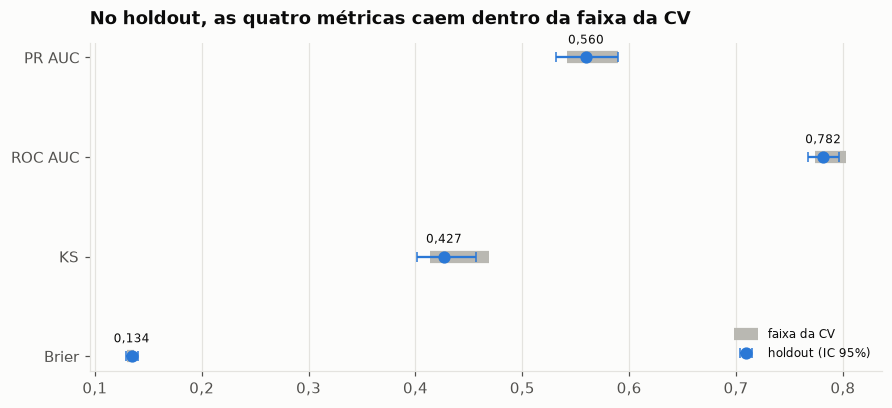

In [28]:
fig, ax = plt.subplots(figsize=(8, 3.6))
names_m = {"pr_auc": "PR AUC", "roc_auc": "ROC AUC", "ks": "KS", "brier": "Brier"}
for i, row in enumerate(ho_metrics.itertuples()):
    ax.plot(
        [row.faixa_inf, row.faixa_sup],
        [i, i],
        color=CONTEXT,
        linewidth=8,
        solid_capstyle="butt",
        label="faixa da CV" if i == 0 else None,
    )
    ax.errorbar(
        row.valor,
        i,
        xerr=[[row.valor - row.ic_inf], [row.ic_sup - row.valor]],
        fmt="o",
        color=HIGHLIGHT,
        ecolor=HIGHLIGHT,
        markersize=7,
        capsize=3,
        label="holdout (IC 95%)" if i == 0 else None,
    )
    ax.annotate(
        f"{row.valor:.3f}".replace(".", ","),
        (row.valor, i),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=8,
    )
ax.set_yticks(range(len(ho_metrics)), [names_m[m] for m in ho_metrics["métrica"]])
ax.invert_yaxis()
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ",")))
ax.legend(loc="lower right", fontsize=8)
ax.set_title("No holdout, as quatro métricas caem dentro da faixa da CV")
save(fig, "final_01_cv_vs_holdout")

**O que encontrei (critério 1 ✅):** as quatro métricas do holdout caem dentro da faixa da CV. O PR AUC do holdout (0,560; IC 0,531–0,589) fica 0,006 abaixo da média da CV (0,566), dentro da variação esperada entre amostras. **A lição do projeto anterior não se repetiu:** lá a CV dizia 0,85 e a realidade foi 0,78; aqui, a CV previu bem o que aconteceu com clientes nunca vistos.

In [29]:
ho_policy = pd.read_csv(config.REPORTS_DIR / "holdout_policy.csv")
ho_boot = pd.read_csv(config.REPORTS_DIR / "holdout_policy_bootstrap.csv")
ho_conf = pd.read_csv(config.REPORTS_DIR / "holdout_confusion.csv", index_col=0)
ho_boot[["diferença", "ic_inf", "ic_sup"]] = ho_boot[["diferença", "ic_inf", "ic_sup"]] / 1e6
print(f"Perda total sem ação no holdout: NT$ {ho_policy['perda_sem_acao'].iloc[0] / 1e6:.1f} mi")
display(
    ho_policy.assign(valor_mi=ho_policy["valor"] / 1e6)[
        ["política", "acionados", "calotes_alcancados", "valor_mi"]
    ].round(3)
)
display(ho_boot.round(2))
ho_conf

Perda total sem ação no holdout: NT$ 40.4 mi


,política,acionados,calotes_alcancados,valor_mi
0,maior valor esperado (modelo),600,296,7.521
1,maior PD (modelo),600,423,5.012
2,regra de atraso (sem modelo),600,413,5.165


,comparação,diferença,ic_inf,ic_sup
0,valor esperado − regra de atraso,2.36,1.59,3.15
1,maior PD − regra de atraso,-0.15,-0.36,0.01


,deu calote,pagou
decisão,,
acionado,296,304
não acionado,1031,4369


**O que encontrei (critério 2 ✅):** acionando 600 clientes (10% do holdout), o valor esperado gera **NT$ 7,52 mi**, contra NT$ 5,17 mi da regra de atraso: **+NT$ 2,36 mi (IC 95%: 1,59 a 3,15 mi), +46%**. A política evita 18,6% da perda total do holdout (NT$ 40,4 mi).

Dos 600 acionados, 296 dariam calote e 304 pagariam: a política aceita acionar bons pagadores com fatura alta, porque o custo de errar (NT$ 400) é pequeno perto do que se evita num caloteiro com dívida grande. 1.031 caloteiros ficam sem ação: é o preço da capacidade limitada.

**Nuance honesta:** no treino, ordenar só pela PD **perdia** da regra com significância; no holdout, a diferença é −0,15 mi (IC −0,36 a +0,01), um **empate**. A conclusão se mantém: a PD sozinha não vence a regra; o ganho vem de combiná-la com a exposição.

In [30]:
fair = pd.read_csv(config.REPORTS_DIR / "holdout_fairness.csv")
fair["alerta_calibracao"] = fair["gap_calibracao"].abs() > config.FAIRNESS_CALIBRATION_GAP
auc_range = fair.groupby("atributo")["roc_auc"].agg(lambda s: s.max() - s.min())
print(
    "Variação de ROC AUC entre grupos:",
    auc_range.round(3).to_dict(),
    "| limite:",
    config.FAIRNESS_AUC_GAP,
)
fair.round(3)

Variação de ROC AUC entre grupos: {'faixa de idade': 0.014, 'sexo': 0.013} | limite: 0.05


,grupo,clientes,taxa_real,pd_media,gap_calibracao,roc_auc,pr_auc,pct_acionados,precisao_acionados,atributo,alerta_calibracao
0,feminino,3598,0.213,0.216,0.004,0.786,0.569,0.094,0.497,sexo,False
1,masculino,2402,0.234,0.227,-0.006,0.774,0.550,0.108,0.488,sexo,False
2,21–30,2181,0.220,0.232,0.012,0.790,0.564,0.091,0.492,faixa de idade,False
3,31–45,2853,0.212,0.208,-0.003,0.776,0.547,0.107,0.469,faixa de idade,False
4,46+,966,0.253,0.232,-0.020,0.781,0.588,0.099,0.573,faixa de idade,False


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/final_02_equidade.png')

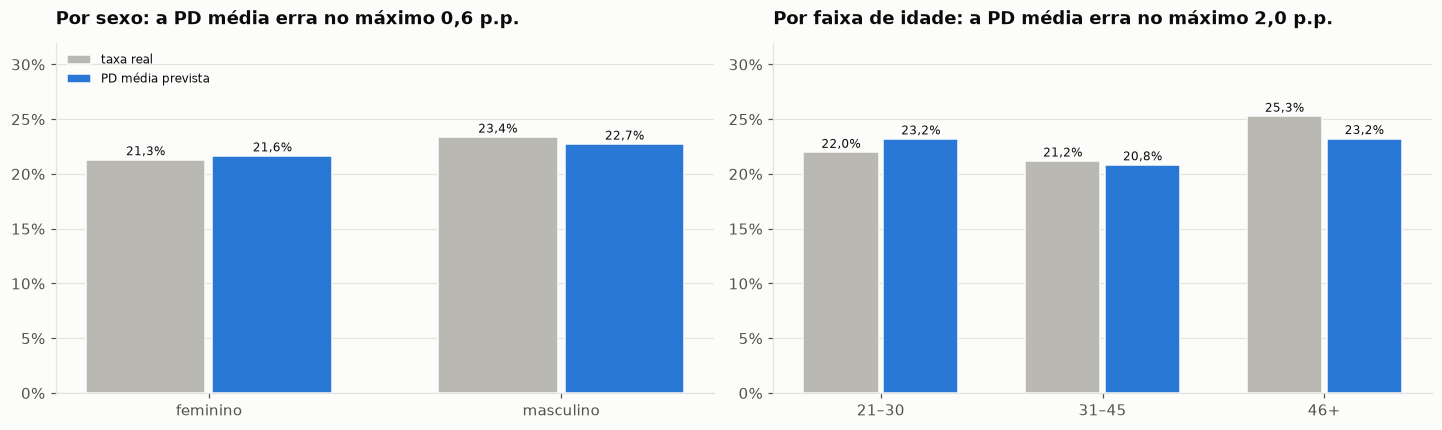

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, attr in zip(axes, ["sexo", "faixa de idade"], strict=True):
    part = fair[fair["atributo"] == attr]
    x = np.arange(len(part))
    ax.bar(x - 0.18, part["taxa_real"], 0.34, color=CONTEXT, label="taxa real", edgecolor=SURFACE)
    ax.bar(
        x + 0.18,
        part["pd_media"],
        0.34,
        color=HIGHLIGHT,
        label="PD média prevista",
        edgecolor=SURFACE,
    )
    for xi, (r_, p_) in enumerate(zip(part["taxa_real"], part["pd_media"], strict=True)):
        ax.annotate(
            pct(r_),
            (xi - 0.18, r_),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            fontsize=8,
        )
        ax.annotate(
            pct(p_),
            (xi + 0.18, p_),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            fontsize=8,
        )
    ax.set_xticks(x, part["grupo"])
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: pct(v, 0)))
    ax.set_ylim(0, 0.32)
    gap_pp = f"{100 * part['gap_calibracao'].abs().max():.1f}".replace(".", ",")
    ax.set_title(f"Por {attr}: a PD média erra no máximo {gap_pp} p.p.")
axes[0].legend(loc="upper left", fontsize=8)
save(fig, "final_02_equidade")

**O que encontrei (critério 3 ✅, nenhum alerta):**
- **Calibração por grupo:** a maior diferença entre a PD média e a taxa real é de **2,0 p.p.** (46+ anos, levemente subestimados), abaixo do limite de 3 p.p.
- **Poder de ordenação:** o ROC AUC varia 0,012 entre os sexos e 0,014 entre as faixas de idade (limite: 0,05).
- **Acionamento:** 10,8% dos homens e 9,4% das mulheres são acionados, uma diferença que acompanha a taxa real de calote (23,4% × 21,3%), e não um viés do modelo. A "precisão" entre os acionados é parecida (49% e 50%).

**Limite desta checagem:** é uma auditoria de **resultados**. Ela não prova a ausência de discriminação indireta, que pode acontecer via variáveis correlacionadas com o grupo (*proxies*), como o limite de crédito. Em produção, essa auditoria vira rotina (Etapa 16).

In [32]:
by_seg = pd.read_csv(config.REPORTS_DIR / "holdout_by_segment.csv")
by_seg.round(3)

,grupo,clientes,taxa_real,pd_media,gap_calibracao,roc_auc,pr_auc,pct_acionados,precisao_acionados
0,atraso crônico,592,0.628,0.591,-0.038,0.677,0.777,0.372,0.686
1,quitadores,2561,0.174,0.168,-0.006,0.726,0.399,0.004,0.200
2,rotativo em dia,2847,0.179,0.191,0.012,0.743,0.445,0.130,0.386


**Por segmento:** o modelo ordena bem quitadores (ROC AUC 0,73) e rotativo em dia (0,74), e pior **dentro** do atraso crônico (0,68), onde quase todos já estão em atraso. Nesse grupo, ele também subestima o risco em 3,8 p.p. (a mesma compressão nas pontas vista na calibração). A política aciona 37% do atraso crônico, 13% do rotativo em dia e quase nenhum quitador (0,4%).

PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/final_03_importancia.png')

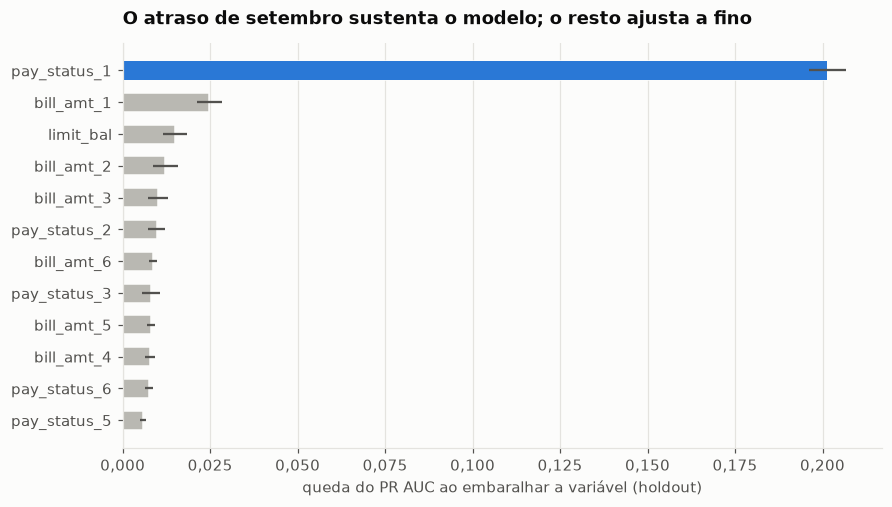

In [33]:
imp = pd.read_csv(config.REPORTS_DIR / "permutation_importance.csv").head(12)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(
    imp["variável"],
    imp["queda_pr_auc"],
    xerr=imp["desvio"],
    color=CONTEXT,
    ecolor=INK_2,
    height=0.6,
    edgecolor=SURFACE,
)
ax.barh(imp["variável"].iloc[:1], imp["queda_pr_auc"].iloc[:1], color=HIGHLIGHT, height=0.6)
ax.invert_yaxis()
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.3f}".replace(".", ",")))
ax.set_xlabel("queda do PR AUC ao embaralhar a variável (holdout)")
ax.set_title("O atraso de setembro sustenta o modelo; o resto ajusta a fino")
save(fig, "final_03_importancia")

PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/final_04_pdp.png')

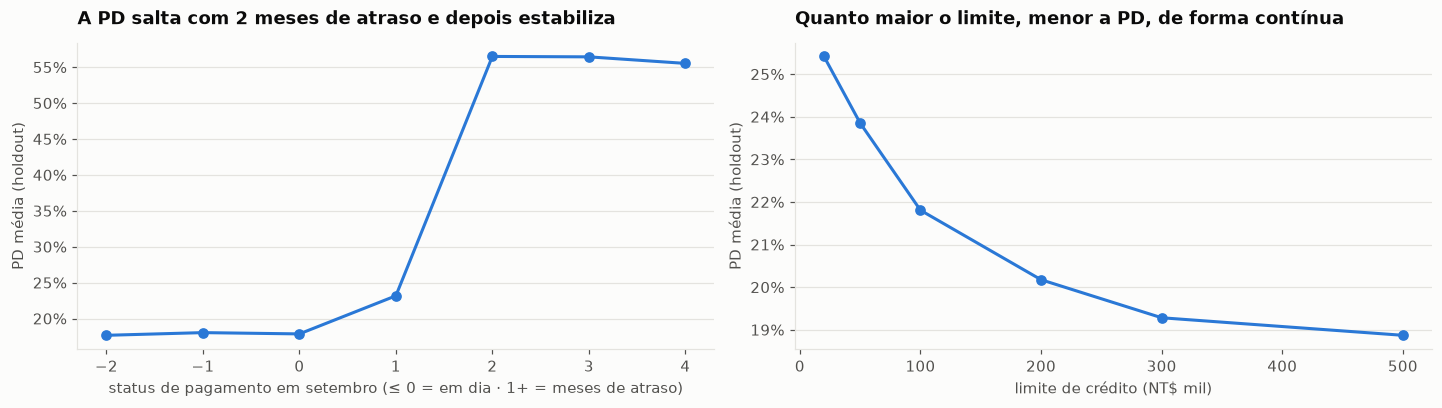

In [34]:
pdp = pd.read_csv(config.REPORTS_DIR / "partial_dependence.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
status = pdp[pdp["variável"] == "pay_status_1"]
axes[0].plot(status["valor"], status["pd_media"], marker="o", color=HIGHLIGHT, linewidth=2)
axes[0].set_xlabel("status de pagamento em setembro (≤ 0 = em dia · 1+ = meses de atraso)")
axes[0].set_title("A PD salta com 2 meses de atraso e depois estabiliza")
limit = pdp[pdp["variável"] == "limit_bal"]
axes[1].plot(limit["valor"] / 1e3, limit["pd_media"], marker="o", color=HIGHLIGHT, linewidth=2)
axes[1].set_xlabel("limite de crédito (NT$ mil)")
axes[1].set_title("Quanto maior o limite, menor a PD, de forma contínua")
for ax in axes:
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: pct(v, 0)))
    ax.set_ylabel("PD média (holdout)")
save(fig, "final_04_pdp")

**O que o modelo usa (holdout):**
- **Importância por permutação** (embaralhar uma variável e medir quanto o modelo piora): o **atraso de setembro** derruba o PR AUC em **0,20**; a seguir vêm a fatura de setembro (0,025) e o limite (0,015). **Sexo, estado civil e idade: importância exatamente zero**, a prova de que o modelo não os usa. Escolaridade, que não foi considerada sensível, tem importância quase nula (0,002).
- **Dependência parcial** (mudar uma variável para todos os clientes e ver a PD média): a PD fica em ≈ 18% para status de -2 a 0, sobe para 23% com 1 mês de atraso e **salta para ≈ 56% com 2 meses**, estabilizando depois. Com o limite, ela cai de forma contínua (25% com NT$ 20 mil, 19% com NT$ 500 mil). As duas formas batem com a EDA e com as razões de chances da logística.

## 12. Conclusão da avaliação final

| Critério (fixado antes) | Resultado | |
|---|---|---|
| PR AUC do holdout dentro da faixa da CV | 0,560 (faixa 0,542–0,590) | ✅ |
| Valor esperado vence a regra de atraso (IC > 0) | +NT$ 2,36 mi (IC 1,59–3,15), +46% | ✅ |
| Equidade: calibração ≤ 3 p.p. e ROC AUC ≤ 0,05 entre grupos | 2,0 p.p. e 0,014 | ✅ |

**O projeto se confirma em clientes nunca vistos.** O modelo foi salvo em `models/final_model.joblib` e é a base das Etapas 14 a 18.

> **O que eu aprendi:** Ver a validação cruzada prever o holdout com diferença de 0,006 foi a recompensa por ter separado a prova no primeiro dia do projeto.

## 13. Quanto está em risco: a perda esperada (Etapa 14, Parte A)

A **perda esperada** (*expected loss*, EL) junta as três peças: **EL = PD × LGD × EAD**. Exemplo: PD de 20%, fatura de NT$ 10.000 e LGD de 60% → 0,20 × 0,60 × 10.000 = **NT$ 1.200**.

Por que isso muda a prioridade, com dois clientes:

| | PD | Fatura | EL |
|---|---|---|---|
| Cliente 1 | 60% | NT$ 2.000 | NT$ 720 |
| Cliente 2 | 25% | NT$ 50.000 | NT$ 7.500 |

Pela PD, o cliente 1 vem primeiro; pela EL, o cliente 2 representa uma perda esperada 10 vezes maior.

Uso as previsões **OOF do treino** e **confirmo** com as previsões do holdout já salvas (sem reavaliá-lo).

In [35]:
if RERUN_EXPERIMENTS:
    from credit_risk.experiments import expected_loss_experiment

    expected_loss_experiment()
el_sum = pd.read_csv(config.REPORTS_DIR / "expected_loss_summary.csv")
el_sens = pd.read_csv(config.REPORTS_DIR / "expected_loss_lgd_sensitivity.csv")
money = ["ead_total", "el_total", "perda_realizada"]
show = el_sum.copy()
show[money] = show[money] / 1e6
display(show.round(3).T)
el_sens.assign(el_total_mi=el_sens["el_total"] / 1e6).drop(columns="el_total").round(1)

,0,1
base,treino (OOF),holdout
clientes,24000,6000
ead_total,1227.005,310.376
el_total,150.368,39.434
perda_realizada,152.814,40.358
el_sobre_ead,0.123,0.127
topo,2400,600
em_comum,1147,299
mudam_de_prioridade,1253,301
el_capturada_por_el,0.561,0.574


,lgd,el_total_mi
0,0.4,112.8
1,0.6,150.4
2,0.8,188.0


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/el_01_concentracao.png')

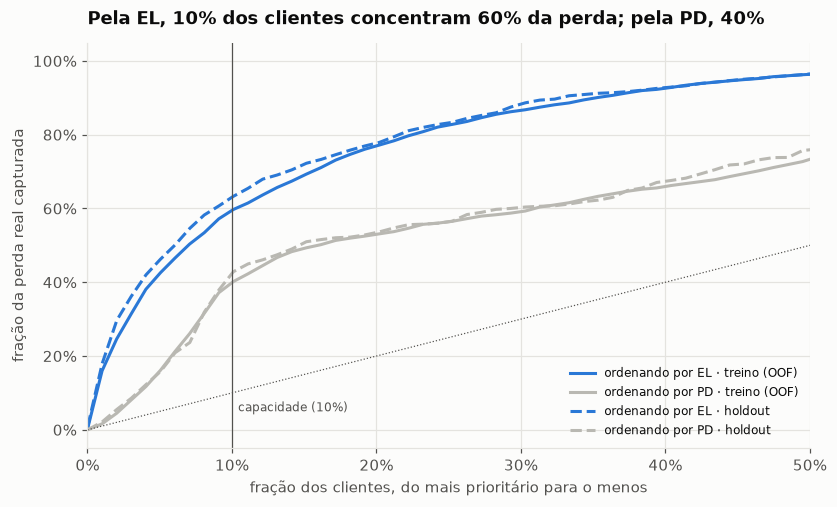

In [36]:
curve = pd.read_csv(config.REPORTS_DIR / "expected_loss_concentration.csv")
fig, ax = plt.subplots(figsize=(7.5, 4.5))
style = {
    ("treino (OOF)", "EL"): (HIGHLIGHT, "-"),
    ("treino (OOF)", "PD"): (CONTEXT, "-"),
    ("holdout", "EL"): (HIGHLIGHT, "--"),
    ("holdout", "PD"): (CONTEXT, "--"),
}
for (base, crit), (color, ls) in style.items():
    part = curve[(curve["base"] == base) & (curve["ordenacao"] == crit)]
    ax.plot(
        part["fracao_clientes"],
        part["fracao_capturada"],
        color=color,
        linestyle=ls,
        linewidth=2,
        label=f"ordenando por {crit} · {base}",
    )
ax.plot([0, 1], [0, 1], color=INK_2, linewidth=0.8, linestyle=":")
ax.axvline(config.CAPACITY, color=INK_2, linewidth=0.8)
ax.annotate(
    "capacidade (10%)",
    (config.CAPACITY, 0.05),
    xytext=(4, 0),
    textcoords="offset points",
    fontsize=8,
    color=INK_2,
)
ax.set_xlim(0, 0.5)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: pct(v, 0)))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: pct(v, 0)))
ax.grid(axis="x")
ax.set_xlabel("fração dos clientes, do mais prioritário para o menos")
ax.set_ylabel("fração da perda real capturada")
ax.legend(loc="lower right", fontsize=8)
ax.set_title("Pela EL, 10% dos clientes concentram 60% da perda; pela PD, 40%")
save(fig, "el_01_concentracao")

**O que encontrei:**
- **A EL acerta a perda da carteira em dinheiro:** NT$ 150,4 mi previstos contra NT$ 152,8 mi reais no treino (−1,6%), e NT$ 39,4 mi contra 40,4 mi no holdout (−2,3%). Com isso, o gestor consegue **provisionar** (reservar dinheiro para perdas) com erro de cerca de 2%.
- **Metade das prioridades muda:** dos 2.400 clientes do top 10% por EL, só 1.147 também estão no top 10% por PD; **1.253 (52%) mudam de prioridade**.
- **A perda é muito concentrada, e a EL a encontra:** o top 10% por EL captura **60%** da perda real (63% no holdout), contra **40%** pelo top 10% por PD (42%). Só os 5% de maior EL já cobrem 43% da perda.
- **Sensibilidade à LGD:** a EL total vai a NT$ 112,8 / 150,4 / 188,0 mi com LGD de 45% / 60% / 75%. A **ordem** dos clientes não muda, porque a LGD é a mesma para todos.

**O que decidi:** a EL é a medida de **"quanto está em risco"** em todo o projeto (dashboard, API, tabela de política). A PD continua sendo a medida de **"quão arriscado é o cliente"**, que vira o score e as faixas na Parte B.

> **O que eu aprendi:** Prioridade por PD e prioridade por perda esperada são listas bem diferentes: metade dos clientes muda de lugar.

## 14. Score de 0 a 1000 e faixas de risco A–E (Etapa 14, Parte B)

O gestor não quer ler "PD = 0,2347". Ele quer uma **nota** e uma **faixa**, cada uma com uma ação. Esta seção usa `scoring.py`, a **fonte única** que a API e o dashboard também usam.

**Do PD ao score.** A "chance de pagar" (*odds*) é a razão entre bons e maus: com PD de 22,1%, ela é 77,9 ÷ 22,1 ≈ 3,5 : 1. O score soma pontos conforme essa chance cresce:

> score = 500 + (60 ÷ ln 2) × ln(chance do cliente ÷ 3,5)

| PD | Chance de pagar | Score |
|---|---|---|
| 22,1% (média da carteira) | 3,5 : 1 | **500** |
| 12,4% | 7 : 1 | **560** |
| 6,6% | 14 : 1 | **620** |
| 36,1% | 1,8 : 1 | **440** |

**PDO = 60** (*points to double the odds*): a cada +60 pontos, a chance de pagar dobra. É a escala usada em scores de mercado (log-odds).

**Faixas A–E:** cortes nos quantis do score **OOF do treino** (A = melhores 30%, B 25%, C 20%, D 15%, E piores 10%), nunca no holdout.

**Prioridade de ação:** a política da Etapa 12 é "acionar os 10% de maior valor esperado", uma regra **de carteira**. Para a API, que recebe um cliente por vez, uso o **valor esperado de corte** (o do cliente na posição 10% no treino): acima dele, o cliente é **prioritário**.

**Critérios fixados antes:** taxa de default crescente de A para E (sem inversão) no treino e no holdout; distribuição por faixa no holdout a no máximo 3 p.p. da do treino.

In [37]:
if RERUN_EXPERIMENTS:
    from credit_risk.experiments import scoring_experiment

    scoring_experiment()
import json

params = json.loads((config.SCORING_PARAMS).read_text())
print("Cortes (score mínimo):", params["band_cuts"])
print(f"Valor esperado de corte para prioridade: NT$ {params['ev_cut']:,.0f}")
bands = pd.read_csv(config.REPORTS_DIR / "score_bands.csv")
for base, g in bands.groupby("base"):
    print(base, "| monotônica:", g.sort_values("faixa")["taxa_default"].is_monotonic_increasing)
wide = bands.pivot(index="faixa", columns="base", values="participacao")
print(
    "Maior desvio de participação (p.p.):",
    round(100 * (wide["holdout"] - wide["treino (OOF)"]).abs().max(), 2),
)

Cortes (score mínimo): {'A': 575.0, 'B': 532.0, 'C': 479.0, 'D': 375.0}
Valor esperado de corte para prioridade: NT$ 4,513
holdout | monotônica: True
treino (OOF) | monotônica: True
Maior desvio de participação (p.p.): 0.88


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/score_01_faixas.png')

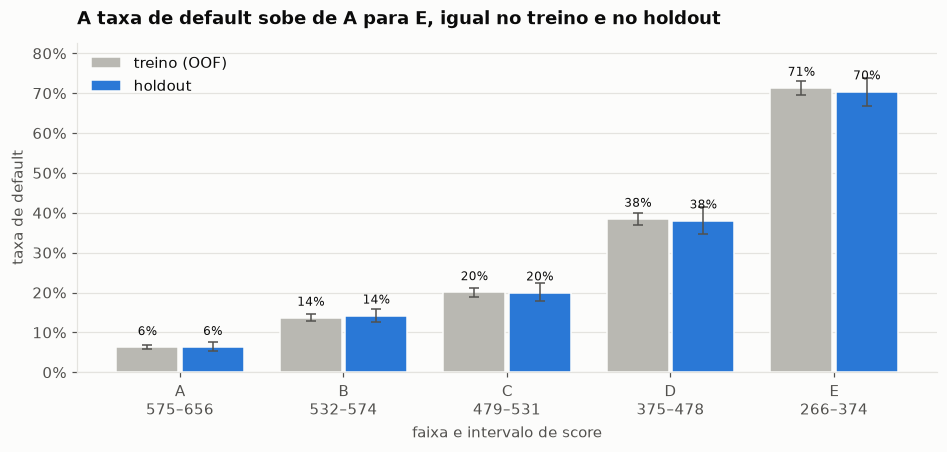

In [38]:
fig, ax = plt.subplots(figsize=(8.5, 4))
letters = list(config.BAND_SHARES)
x = np.arange(len(letters))
for offset, (base, color) in zip(
    [-0.2, 0.2], [("treino (OOF)", CONTEXT), ("holdout", HIGHLIGHT)], strict=True
):
    g = bands[bands["base"] == base].set_index("faixa").loc[letters]
    ax.bar(x + offset, g["taxa_default"], 0.38, color=color, label=base, edgecolor=SURFACE)
    ax.errorbar(
        x + offset,
        g["taxa_default"],
        yerr=[g["taxa_default"] - g["ic_inf"], g["ic_sup"] - g["taxa_default"]],
        fmt="none",
        ecolor=INK_2,
        capsize=3,
        elinewidth=1,
    )
    for xi, v in zip(x + offset, g["taxa_default"], strict=True):
        ax.annotate(
            pct(v, 0), (xi, v), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8
        )
tr = bands[bands["base"] == "treino (OOF)"].set_index("faixa").loc[letters]
ax.set_xticks(
    x,
    [
        f"{b}\n{int(lo)}–{int(hi)}"
        for b, lo, hi in zip(letters, tr["score_min"], tr["score_max"], strict=True)
    ],
)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: pct(v, 0)))
ax.set_ylabel("taxa de default")
ax.set_xlabel("faixa e intervalo de score")
ax.margins(y=0.12)
ax.legend(loc="upper left")
ax.set_title("A taxa de default sobe de A para E, igual no treino e no holdout")
save(fig, "score_01_faixas")

In [39]:
ho = bands[bands["base"] == "holdout"].set_index("faixa").loc[letters]
policy_table = pd.DataFrame(
    {
        "ação": ho["acao"],
        "clientes": ho["clientes"],
        "participação": (100 * ho["participacao"]).round(1),
        "taxa de default (%)": (100 * ho["taxa_default"]).round(1),
        "perda esperada (NT$ mi)": (ho["perda_esperada"] / 1e6).round(2),
        "perda real (NT$ mi)": (ho["perda_real"] / 1e6).round(2),
        "prioritários p/ ação": ho["prioritarios"],
    }
)
policy_table

,ação,clientes,participação,taxa de default (%),perda esperada (NT$ mi),perda real (NT$ mi),prioritários p/ ação
faixa,,,,,,,
A,elegível a aumento de limite e ofertas,1787,29.8,6.3,5.06,3.89,16
B,relacionamento padrão,1540,25.7,14.2,6.84,7.48,112
C,"relacionamento padrão, com monitoramento",1213,20.2,20.0,5.81,6.38,98
D,monitoramento próximo,842,14.0,38.0,5.38,5.09,102
E,candidato prioritário a ação preventiva,618,10.3,70.4,16.33,17.50,319


**O que encontrei:**
- **Monotonicidade ✅:** a taxa de default sobe de **6% (A)** para **14% (B)**, **20% (C)**, **38% (D)** e **71% (E)**, quase igual no holdout. Os intervalos de confiança de faixas vizinhas nem se encostam.
- **Estabilidade ✅:** no holdout, a participação de cada faixa difere no máximo 0,9 p.p. da do treino.
- **A faixa E** (10% dos clientes) concentra cerca de **40% da perda real**.
- **Faixa e prioridade se complementam:** a faixa diz **quão arriscado** é o cliente; a prioridade diz **onde agir rende mais**. No holdout, 112 clientes da faixa **B** são prioritários (risco moderado, mas dívidas grandes). Uma política "acionar a faixa E" deixaria esses clientes de fora.
- O score real ocupa cerca de **266 a 656** da escala 0–1000. Isso é esperado: com PDO de 60, um score de 1000 exigiria uma PD de cerca de 0,01%. A escala é uma convenção; o que importa é a ordem e o significado documentado (+60 pontos = chance de pagar dobra).

**Tabela de política (holdout):** é a peça que o gestor usa. Cada faixa tem uma ação; dentro da capacidade, o **valor esperado** decide quem é acionado primeiro.

> **O que eu aprendi:** Faixa e prioridade respondem a perguntas diferentes ("quão arriscado?" e "onde agir rende mais?"). Misturar as duas deixaria de fora clientes com dívidas grandes.

## 15. Por que essa decisão? Os motivos de cada cliente (Etapa 15)

Um cliente na faixa E pergunta "por quê?". Os **motivos da decisão** (*reason codes*) são os fatores que **mais aumentaram** o risco **daquele** cliente, numa frase de negócio.

**Como:** o **SHAP** divide a previsão de cada cliente em contribuições de cada variável, como dividir a conta de um jantar pelo que cada pessoa consumiu: risco médio + soma das contribuições = risco do cliente (em log-odds). Para árvores, o cálculo é exato (*TreeSHAP*). Uso a versão nativa do XGBoost, que é o mesmo algoritmo da biblioteca `shap` (um teste confere que os valores são iguais) e evita uma incompatibilidade conhecida entre as versões das duas bibliotecas.

**Agrupando por conceito:** o modelo tem várias colunas de atraso (colineares, Etapa 9). Sem agrupar, os três motivos seriam "atraso, atraso, atraso". As contribuições são somadas em 7 conceitos de negócio (atraso recente, histórico de atraso, uso do limite, pagamentos, limite, valor da fatura, perfil cadastral) antes de escolher os 3 maiores.

**Critérios fixados antes:** aditividade (erro < 0,0001); na faixa E, o 1º motivo mais frequente é um conceito de atraso; cliente sem fator relevante recebe "sem fatores de risco relevantes".

**Dois ajustes feitos depois de ver os primeiros resultados** (afetam só a **apresentação**, não o score, a faixa nem a decisão):
1. **Materialidade:** na faixa A, 26% dos clientes recebiam "escolaridade" como 1º motivo, com contribuição desprezível (no máximo +2% na chance de calote). Agora um fator só vira motivo se aumentar a chance de calote em pelo menos ≈ 5% (0,05 em log-odds). Decidi isso depois de ver o resultado, e deixo registrado.
2. **Linguagem:** frases como "pagou 100% da fatura" soavam como elogio. Agora dizem o comportamento que pesou: "fatura zerada em setembro (cartão sem uso recente)", que tem mesmo default acima da média (24,8% contra 22,1%), ou "comportamento de pagamento: pagou 100% da fatura anterior", a confusão vista na Etapa 9.

In [40]:
if RERUN_EXPERIMENTS:
    from credit_risk.experiments import reasons_experiment

    reasons_experiment()
r_sum = pd.read_csv(config.REPORTS_DIR / "reasons_summary.csv")
r_imp = pd.read_csv(config.REPORTS_DIR / "reasons_concept_importance.csv")
r_band = pd.read_csv(config.REPORTS_DIR / "reasons_by_band.csv")
display(r_sum.round(4))
r_imp.round(4)

,erro_max_aditividade,pct_sem_motivo,media_motivos
0,0.0,0.2215,1.5363


,conceito,media_abs_shap
0,histórico de atraso,0.5287
1,atraso recente,0.2798
2,pagamentos,0.1838
3,uso do limite,0.1423
4,valor da fatura,0.1083
5,limite de crédito,0.0827
6,perfil cadastral,0.0117


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/reasons_01_por_faixa.png')

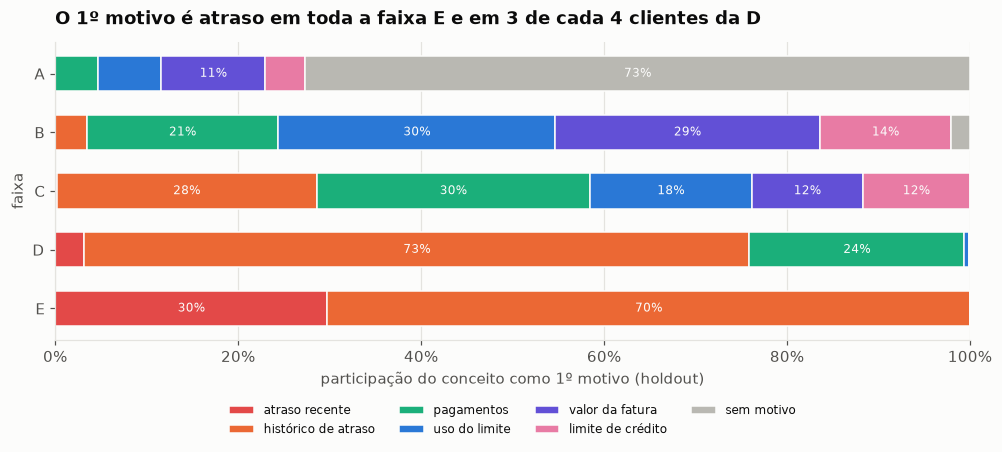

In [41]:
first = r_band.pivot(index="faixa", columns="motivo_1", values="participacao").fillna(0)
order = [
    "atraso recente",
    "histórico de atraso",
    "pagamentos",
    "uso do limite",
    "valor da fatura",
    "limite de crédito",
    "sem motivo",
]
first = first[[c for c in order if c in first.columns]]
colors = ["#e34948", "#eb6834", "#1baf7a", "#2a78d6", "#6250d6", "#e87ba4", CONTEXT]
fig, ax = plt.subplots(figsize=(9, 4))
left = np.zeros(len(first))
for col, color in zip(first.columns, colors, strict=False):
    ax.barh(
        first.index, first[col], left=left, color=color, label=col, edgecolor=SURFACE, height=0.6
    )
    for i, (start, v) in enumerate(zip(left, first[col], strict=True)):
        if v >= 0.08:
            ax.annotate(
                pct(v, 0), (start + v / 2, i), ha="center", va="center", fontsize=8, color=SURFACE
            )
    left += first[col].to_numpy()
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: pct(v, 0)))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_ylabel("faixa")
ax.set_xlabel("participação do conceito como 1º motivo (holdout)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4, fontsize=8)
ax.set_title("O 1º motivo é atraso em toda a faixa E e em 3 de cada 4 clientes da D")
save(fig, "reasons_01_por_faixa")

In [42]:
pd.set_option("display.max_colwidth", 200)
pd.read_csv(config.REPORTS_DIR / "reasons_examples.csv")[
    ["faixa", "score", "prioritario", "motivos"]
]

,faixa,score,prioritario,motivos
0,E,333,False,2 meses de atraso no último pagamento · atraso em 1 dos últimos 6 meses (pior atraso: 2 meses) · comportamento de pagamento: pagou 9% da fatura anterior
1,E,344,True,2 meses de atraso no último pagamento · atraso em 1 dos últimos 6 meses (pior atraso: 2 meses) · usa 98% do limite
2,D,440,False,atraso em 4 dos últimos 6 meses (pior atraso: 2 meses)
3,D,468,False,atraso em 1 dos últimos 6 meses (pior atraso: 2 meses) · comportamento de pagamento: pagou 0% da fatura anterior · fatura de NT$ 2 mil
4,C,481,False,comportamento de pagamento: pagou 100% da fatura anterior · fatura de NT$ 390 · cartão quase sem uso (usa 0% do limite)
5,C,512,False,fatura zerada em setembro (cartão sem uso recente) · comportamento de pagamento: pagou 100% da fatura anterior
6,B,545,False,fatura de NT$ 312 · comportamento de pagamento: pagou 100% da fatura anterior
7,B,561,False,fatura de NT$ 295
8,A,580,False,comportamento de pagamento: pagou 8% da fatura anterior
9,A,606,False,sem fatores de risco relevantes


**O que encontrei:**
- **Aditividade ✅:** erro máximo de 0,0: risco médio + contribuições = risco previsto, para todos os clientes.
- **Coerência ✅:** na faixa E, o 1º motivo é sempre atraso (histórico em 70% dos casos, recente em 30%). Na faixa D, o histórico de atraso responde por 73%. Na importância global (média do |SHAP|), os dois conceitos de atraso também lideram (0,53 e 0,28), como na importância por permutação da Etapa 13.
- **Faixas de baixo risco:** 73% dos clientes da faixa A não têm nenhum fator relevante e recebem "sem fatores de risco relevantes". Nas faixas B e C, os motivos são de uso e pagamento (cartão quase sem uso, fatura baixa), e não de atraso.
- **Os exemplos são lidos por qualquer pessoa:** "2 meses de atraso no último pagamento · atraso em 1 dos últimos 6 meses · usa 98% do limite".

**O que decidi:** os motivos entram em `scoring.score_clients` (fonte única). A API e o dashboard devolvem score, faixa, ação, prioridade **e motivos** juntos.

> **O que eu aprendi:** Explicar não é só calcular o SHAP. Sem agrupar por conceito e sem um limite de materialidade, os motivos estavam corretos, mas não ajudavam ninguém.

## 16. Quando o modelo envelhece: monitoramento (Etapa 16)

Um modelo é treinado com a "foto" de um momento. Se o público mudar (crise, nova campanha, outro canal de captação), ele continua respondendo, mas pode estar errado sem avisar. O monitoramento é o **alarme de fumaça**: compara cada lote novo com a população de treino.

**PSI** (*Population Stability Index*): divide os clientes em faixas e soma, faixa a faixa, (atual − referência) × ln(atual ÷ referência). Exemplo: 50%/50% → 70%/30% dá 0,067 + 0,102 = **0,17**. Leitura de mercado: < 0,10 estável · 0,10–0,25 atenção · > 0,25 investigar.

A **referência** (decis de cada variável numérica, categorias do status, proporções) é definida **uma vez com o treino** e salva em `reports/monitoring_reference.json`. A função `monitoring.run_monitoring(lote)` é a tarefa que um agendador chamaria todo mês.

**Critérios fixados antes:** holdout com PSI < 0,10 em tudo; nos cenários deslocados, o alarme (> 0,25) precisa disparar no score ou em pelo menos uma variável.

In [43]:
import json

if RERUN_EXPERIMENTS:
    from credit_risk.monitoring import main as run_monitor

    run_monitor()
mon = json.loads(config.MONITORING_REPORT.read_text())
psi_table = pd.DataFrame({r["lote"]: {k: v["psi"] for k, v in r["variaveis"].items()} for r in mon})
ind_table = pd.DataFrame(
    {r["lote"]: {f"{k} (razão)": v["razao"] for k, v in r["indicadores"].items()} for r in mon}
)
display(pd.concat([psi_table, ind_table]).round(3))
pd.DataFrame(
    [
        {
            "lote": r["lote"],
            "clientes": r["clientes"],
            "status": r["status_geral"],
            "alertas": ", ".join(r["alertas"]) or "—",
        }
        for r in mon
    ]
)

,holdout (mesma população),só clientes até 25 anos,só limite até NT$ 50 mil,crise: dobra a fração de atrasados
score,0.002,0.178,1.300,0.066
pd,0.001,0.176,1.279,0.066
util_recent,0.001,0.161,0.389,0.014
pay_ratio_recent,0.001,0.166,0.338,0.015
bill_amt_1,0.002,0.250,1.268,0.010
limit_bal,0.002,0.816,5.887,0.007
age,0.003,7.309,0.210,0.004
pay_status_1,0.003,0.129,0.206,0.090
delay_months,0.001,0.034,0.104,0.061
pd_media (razão),1.001,1.249,1.433,1.228


,lote,clientes,status,alertas
0,holdout (mesma população),6000,estável,—
1,só clientes até 25 anos,767,investigar,"score, pd, util_recent, pay_ratio_recent, bill_amt_1, limit_bal, age, pay_status_1, pd_media, fracao_faixa_e"
2,só limite até NT$ 50 mil,1530,investigar,"score, pd, util_recent, pay_ratio_recent, bill_amt_1, limit_bal, age, pay_status_1, delay_months, pd_media, fracao_faixa_e"
3,crise: dobra a fração de atrasados,7324,investigar,"pd_media, fracao_faixa_e"


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/monitor_01_cenarios.png')

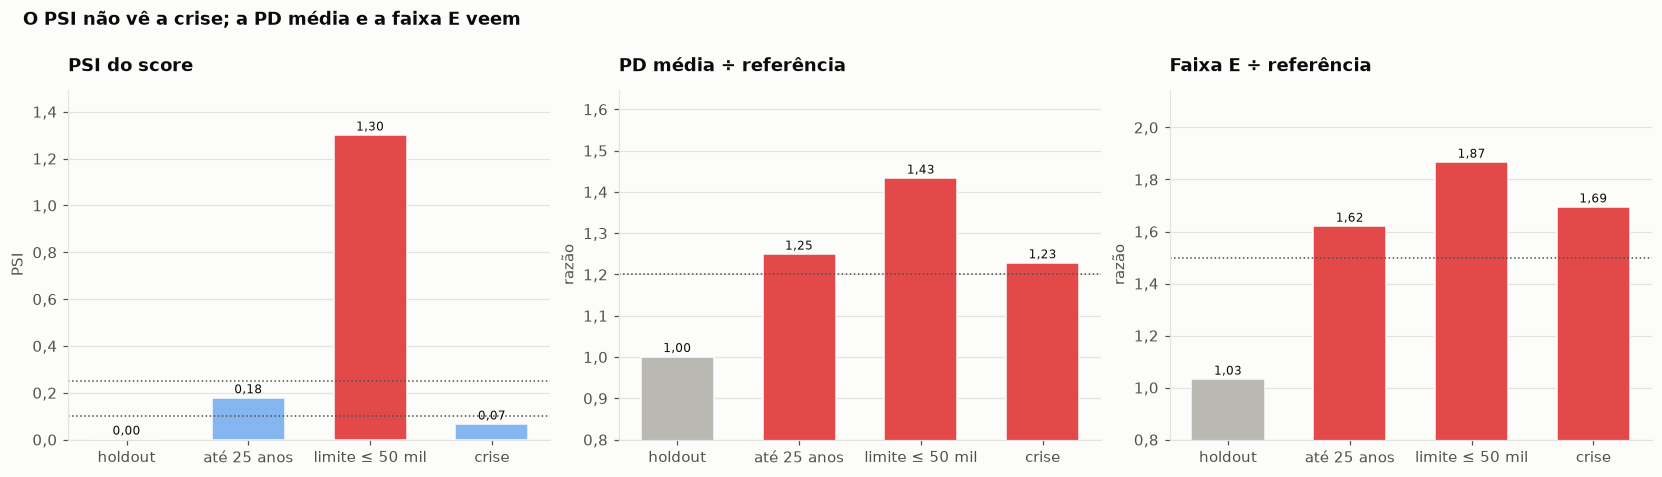

In [44]:
from credit_risk.viz import ALERT

short = ["holdout", "até 25 anos", "limite ≤ 50 mil", "crise"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
series = [
    ("PSI do score", [r["variaveis"]["score"]["psi"] for r in mon], [0.10, 0.25], "PSI"),
    (
        "PD média ÷ referência",
        [r["indicadores"]["pd_media"]["razao"] for r in mon],
        [config.PD_MEAN_RATIO_MAX],
        "razão",
    ),
    (
        "Faixa E ÷ referência",
        [r["indicadores"]["fracao_faixa_e"]["razao"] for r in mon],
        [config.BAND_E_RATIO_MAX],
        "razão",
    ),
]
for ax, (title, vals, limits, ylabel) in zip(axes, series, strict=True):
    colors = [
        ALERT if v > limits[-1] else (CONTEXT if i == 0 else "#86b6ef") for i, v in enumerate(vals)
    ]
    ax.bar(short, vals, color=colors, width=0.6, edgecolor=SURFACE)
    for lim in limits:
        ax.axhline(lim, color=INK_2, linestyle=":", linewidth=1)
    for i, v in enumerate(vals):
        ax.annotate(
            f"{v:.2f}".replace(".", ","),
            (i, v),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            fontsize=8,
        )
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if ylabel == "PSI":
        ax.set_ylim(0, max(vals) * 1.15)
    else:
        ax.set_ylim(0.8, max(vals) * 1.15)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ",")))
fig.suptitle(
    "O PSI não vê a crise; a PD média e a faixa E veem",
    x=0.01,
    ha="left",
    fontweight="bold",
    y=1.10,
)
save(fig, "monitor_01_cenarios")

**O que encontrei:**
- **Holdout ✅:** PSI ≤ 0,003 em todas as variáveis; PD média 1,00× e faixa E 1,03× a referência. Mesma população, nenhum alarme falso.
- **Só limite até NT$ 50 mil**: o alarme (> 0,25) dispara no PSI do score (1,30) e de quase todas as variáveis. **Só clientes até 25 anos**: o score fica em "atenção" (0,18), e o alarme dispara na idade, no limite e na fatura (variáveis de entrada). Nos dois casos, os indicadores complementares também disparam.
- ⚠️ **Crise (dobro de atrasados, de 22% para 36%): o PSI ficou "estável"** (0,066 no score; 0,090 no status de setembro). O PSI mede a **forma da distribuição inteira** em 10 faixas; quando a mudança se concentra na **cauda de maior risco**, o efeito se dilui na soma. Só que essa cauda é onde está o dinheiro: a PD média subiu **23%**, e a provisão calculada pela EL ficaria 23% defasada sem ninguém perceber.

**O que decidi (depois de ver este resultado, por isso registrado):** acrescentar dois **indicadores complementares**, com limites justificados pelo negócio: **PD média > 1,2× a referência** (provisão mais de 20% defasada) e **fração na faixa E > 1,5× a referência** (a capacidade de ação foi dimensionada para cerca de 10%). Com eles, a crise dispara (1,23× e 1,69×) e o holdout continua estável. Como os limites vieram depois do resultado, isso fica registrado; a verdadeira validação deles será em lotes reais.

### Como isso vira rotina mensal em produção

1. **Todo mês**, um agendador (aqui, um workflow `schedule` no GitHub Actions, Etapa 19) chama `run_monitoring` com o lote do mês e publica `monitoring.json`.
2. **Status "atenção":** o time de risco revisa as variáveis que mudaram e confere se é sazonal.
3. **Status "investigar":** congela mudanças de política, compara a PD prevista com o default real assim que ele chegar (1 mês depois) e avalia **recalibrar** (barato) ou **retreinar** (caro) o modelo.
4. **Monitoramento de desempenho:** o PSI olha a entrada; quando o desfecho chega, mede-se também PR AUC, calibração por faixa e o valor da política, os mesmos critérios das Etapas 12 a 14.

Em uma operação maior, essa mesma função seria uma tarefa de uma DAG no Airflow (extrair o lote → pontuar → calcular o PSI → alertar). Aqui, com um único job mensal e 30 mil clientes, o Airflow seria infraestrutura sem necessidade (decisão registrada no README).

> **O que eu aprendi:** O índice padrão do mercado falhou justamente no cenário que mais importa. Só percebi porque testei o alarme com uma crise simulada, em vez de confiar na régua de mercado.

## 17. O que eu concluí

| Pergunta | Resposta | Seção |
|---|---|---|
| Qual modelo? | **XGBoost ajustado, sozinho**, sem balanceamento, sem calibração, sem ensemble e sem sexo, estado civil ou idade | 1–8, 10 |
| Ele se confirma em clientes nunca vistos? | Sim: PR AUC 0,560 no holdout × 0,566 na CV | 11 |
| Quanto vale? | Acionando 600 clientes (10% do holdout): **NT$ 7,52 mi**, **+NT$ 2,36 mi (+46%)** sobre a regra de atraso (IC 95%: +1,59 a +3,15 mi), evitando 18,6% da perda | 9, 11 |
| É justo? | Calibração por sexo e idade com erro ≤ 2,0 p.p. | 11 |
| Quanto está em risco? | Perda esperada com erro de −2,3% no holdout; o top 10% por EL concentra 63% da perda | 13 |
| O que fazer com cada cliente? | Score 0–1000, faixas A–E (calote de 6% a 71%) e prioridade pelo valor esperado | 14 |
| Por quê? | Até 3 motivos por cliente, em português | 15 |
| E amanhã? | Monitoramento mensal com PSI + PD média + faixa E | 16 |

**Minha recomendação:** adotar a política de acionar, todo mês, os 10% de clientes com maior valor esperado de ação, começando por um **piloto com grupo de controle**. A eficácia da ação (30%) é a premissa que mais pesa no valor, e ela só pode ser medida na prática.

**O que eu levo deste projeto:**
1. **O objetivo é dinheiro, não métrica.** A melhor PD sozinha empatou com uma regra simples; o ganho veio de combiná-la com a exposição.
2. **Critério antes, resultado depois.** Balanceamento, ensemble e calibração foram rejeitados por regra, e o sistema ficou mais simples e mais fácil de explicar.
3. **Uma prova lacrada de verdade muda a confiança no resultado.** No meu projeto anterior, a validação prometeu 0,85 e entregou 0,78; aqui, prometeu 0,566 e entregou 0,560.
4. **Resultado negativo também é resultado**, e eu documentei cada um.

Limitações e próximos passos estão nas [Conclusões do relatório](../docs/RELATORIO.md#4-conclusões); a ficha do modelo, no [model card](../docs/model_card.md).